In [1]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [2]:
from pathlib import Path

# Location of the dataset folder
data_folder = Path("../data/raw")

# Display available CSV files
csv_files = list(data_folder.glob("*.csv"))

print("Folder exists:", data_folder.exists())
print("CSV files found:", len(csv_files))

for file in csv_files:
    print("Filename:", file.name)
    print("Size (MB):", round(file.stat().st_size / (1024**2), 2))

Folder exists: True
CSV files found: 2
Filename: Expresso_churn_100k.csv
Size (MB): 11.56
Filename: Expresso_churn_dataset.csv
Size (MB): 247.03


In [3]:
import pandas as pd

file_path = "../data/raw/Expresso_churn_dataset.csv"

# Read only the first 1,000 rows
sample = pd.read_csv(file_path, nrows=1000)

print("Sample shape:", sample.shape)

print("\nColumn names:")
print(sample.columns.tolist())

print("\nData types:")
print(sample.dtypes)

print("\nFirst 5 rows:")
display(sample.head())

Sample shape: (1000, 19)

Column names:
['user_id', 'REGION', 'TENURE', 'MONTANT', 'FREQUENCE_RECH', 'REVENUE', 'ARPU_SEGMENT', 'FREQUENCE', 'DATA_VOLUME', 'ON_NET', 'ORANGE', 'TIGO', 'ZONE1', 'ZONE2', 'MRG', 'REGULARITY', 'TOP_PACK', 'FREQ_TOP_PACK', 'CHURN']

Data types:
user_id            object
REGION             object
TENURE             object
MONTANT           float64
FREQUENCE_RECH    float64
REVENUE           float64
ARPU_SEGMENT      float64
FREQUENCE         float64
DATA_VOLUME       float64
ON_NET            float64
ORANGE            float64
TIGO              float64
ZONE1             float64
ZONE2             float64
MRG                object
REGULARITY          int64
TOP_PACK           object
FREQ_TOP_PACK     float64
CHURN               int64
dtype: object

First 5 rows:


,user_id,REGION,TENURE,MONTANT,FREQUENCE_RECH,REVENUE,ARPU_SEGMENT,FREQUENCE,DATA_VOLUME,ON_NET,ORANGE,TIGO,ZONE1,ZONE2,MRG,REGULARITY,TOP_PACK,FREQ_TOP_PACK,CHURN
0,00000bfd7d50f01092811bc0c8d7b0d6fe7c3596,FATICK,K > 24 month,4250.0,15.0,4251.0,1417.0,17.0,4.0,388.0,46.0,1.0,1.0,2.0,NO,54,On net 200F=Unlimited _call24H,8.0,0
1,00000cb4a5d760de88fecb38e2f71b7bec52e834,NaN,I 18-21 month,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NO,4,NaN,NaN,1
2,00001654a9d9f96303d9969d0a4a851714a4bb57,NaN,K > 24 month,3600.0,2.0,1020.0,340.0,2.0,NaN,90.0,46.0,7.0,NaN,NaN,NO,17,On-net 1000F=10MilF;10d,1.0,0
3,00001dd6fa45f7ba044bd5d84937be464ce78ac2,DAKAR,K > 24 month,13500.0,15.0,13502.0,4501.0,18.0,43804.0,41.0,102.0,2.0,NaN,NaN,NO,62,"Data:1000F=5GB,7d",11.0,0
4,000028d9e13a595abe061f9b58f3d76ab907850f,DAKAR,K > 24 month,1000.0,1.0,985.0,328.0,1.0,NaN,39.0,24.0,NaN,NaN,NaN,NO,11,Mixt 250F=Unlimited_call24H,2.0,0


In [4]:
import pandas as pd
from pathlib import Path

file_path = Path("../data/raw/Expresso_churn_dataset.csv")

total_rows = 0
missing_counts = None
churn_counts = {}
duplicate_ids = 0
seen_ids = set()

for chunk in pd.read_csv(file_path, chunksize=50_000):

    total_rows += len(chunk)

    # Count missing values in every column
    current_missing = chunk.isna().sum()
    if missing_counts is None:
        missing_counts = current_missing
    else:
        missing_counts += current_missing

    # Count the target classes
    counts = chunk["CHURN"].value_counts(dropna=False)
    for label, count in counts.items():
        churn_counts[label] = churn_counts.get(label, 0) + int(count)

    # Check duplicate customer IDs
    ids = chunk["user_id"].dropna()
    duplicate_ids += int(ids.duplicated().sum())
    new_ids = set(ids) - seen_ids
    seen_ids.update(new_ids)

print("Total rows:", total_rows)
print("Total columns:", len(missing_counts))

print("\nCHURN distribution:")
print(pd.Series(churn_counts).sort_index())

print("\nMissing values by column:")
print(missing_counts.sort_values(ascending=False))

print("\nDuplicate IDs within chunks:", duplicate_ids)

Total rows: 2154048
Total columns: 19

CHURN distribution:
0    1750062
1     403986
dtype: int64

Missing values by column:
ZONE2             2017224
ZONE1             1984327
TIGO              1290016
DATA_VOLUME       1060433
TOP_PACK           902594
FREQ_TOP_PACK      902594
ORANGE             895248
REGION             849299
ON_NET             786675
MONTANT            756739
FREQUENCE_RECH     756739
FREQUENCE          726048
ARPU_SEGMENT       726048
REVENUE            726048
user_id                 0
TENURE                  0
MRG                     0
REGULARITY              0
CHURN                   0
dtype: int64

Duplicate IDs within chunks: 0


In [5]:
import pandas as pd

file_path = "../data/raw/Expresso_churn_dataset.csv"

df_sample = pd.read_csv(file_path, nrows=50_000)

# Inspect missingness and data types
profile = pd.DataFrame({
    "dtype": df_sample.dtypes.astype(str),
    "missing_count": df_sample.isna().sum(),
    "missing_percent": (
        df_sample.isna().mean() * 100
    ).round(2),
    "unique_values": df_sample.nunique()
})

display(profile.sort_values(
    "missing_percent", ascending=False
))

print("\nTarget values:")
print(df_sample["CHURN"].value_counts(dropna=False))

print("\nSample categorical values:")
for col in ["REGION", "TENURE", "MRG", "TOP_PACK"]:
    print(f"\n{col}:")
    print(df_sample[col].value_counts(dropna=False).head(10))

,dtype,missing_count,missing_percent,unique_values
ZONE2,float64,46799,93.60,108
ZONE1,float64,45990,91.98,146
TIGO,float64,29853,59.71,419
DATA_VOLUME,float64,24512,49.02,7740
TOP_PACK,object,20990,41.98,88
FREQ_TOP_PACK,float64,20990,41.98,115
ORANGE,float64,20772,41.54,1085
REGION,object,19617,39.23,14
ON_NET,float64,18307,36.61,2525
MONTANT,float64,17582,35.16,987



Target values:
CHURN
0    40608
1     9392
Name: count, dtype: int64

Sample categorical values:

REGION:
REGION
NaN            19617
DAKAR          11955
THIES           4247
SAINT-LOUIS     2727
LOUGA           2305
KAOLACK         2263
DIOURBEL        1589
TAMBACOUNDA     1267
KAFFRINE        1013
FATICK           882
Name: count, dtype: int64

TENURE:
TENURE
K > 24 month     47482
I 18-21 month     1006
H 15-18 month      581
G 12-15 month      349
J 21-24 month      299
F 9-12 month       217
E 6-9 month         46
D 3-6 month         20
Name: count, dtype: int64

MRG:
MRG
NO    50000
Name: count, dtype: int64

TOP_PACK:
TOP_PACK
NaN                                          20990
All-net 500F=2000F;5d                         7229
On net 200F=Unlimited _call24H                3557
Data:490F=1GB,7d                              2740
Data: 100 F=40MB,24H                          2000
Mixt 250F=Unlimited_call24H                   1585
MIXT:500F= 2500F on net _2500F off net;2d     1552

In [6]:
import pandas as pd

file_path = "../data/raw/Expresso_churn_dataset.csv"

total_rows = 0
missing_target = 0
invalid_target = 0
target_counts = {}

for chunk in pd.read_csv(file_path, chunksize=50_000):

    total_rows += len(chunk)

    missing_target += int(chunk["CHURN"].isna().sum())

    invalid_target += int(
        (~chunk["CHURN"].isin([0, 1]) & chunk["CHURN"].notna()).sum()
    )

    counts = chunk["CHURN"].value_counts(dropna=False)

    for value, count in counts.items():
        target_counts[value] = target_counts.get(value, 0) + int(count)

print("Total rows:", total_rows)
print("Missing target values:", missing_target)
print("Invalid target values:", invalid_target)
print("Full target distribution:", target_counts)

Total rows: 2154048
Missing target values: 0
Invalid target values: 0
Full target distribution: {0: 1750062, 1: 403986}


In [7]:
import pandas as pd
from pathlib import Path

source = Path("../data/raw/Expresso_churn_dataset.csv")
output = Path("../data/raw/Expresso_churn_100k.csv")

sample_size = 100_000
random_state = 42

# Approximate class proportions from your validation
churn_rate = 403986 / 2154048
churn_sample_size = round(sample_size * churn_rate)
non_churn_sample_size = sample_size - churn_sample_size

churn_parts = []
non_churn_parts = []

for chunk in pd.read_csv(source, chunksize=50_000):
    churn_parts.append(chunk[chunk["CHURN"] == 1])
    non_churn_parts.append(chunk[chunk["CHURN"] == 0])

churn_df = pd.concat(churn_parts, ignore_index=True)
non_churn_df = pd.concat(non_churn_parts, ignore_index=True)

sample = pd.concat([
    churn_df.sample(n=churn_sample_size, random_state=random_state),
    non_churn_df.sample(n=non_churn_sample_size, random_state=random_state)
], ignore_index=True)

sample = sample.sample(frac=1, random_state=random_state).reset_index(drop=True)
sample.to_csv(output, index=False)

print("Saved to:", output)
print("Sample shape:", sample.shape)
print("Churn distribution:")
print(sample["CHURN"].value_counts())
print("Churn rate:", round(sample["CHURN"].mean() * 100, 2), "%")

Saved to: ..\data\raw\Expresso_churn_100k.csv
Sample shape: (100000, 19)
Churn distribution:
CHURN
0    81245
1    18755
Name: count, dtype: int64
Churn rate: 18.76 %


In [8]:
import pandas as pd

file_path = "../data/raw/Expresso_churn_100k.csv"
df = pd.read_csv(file_path)

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nData types:")
print(df.dtypes)

print("\nMissing values:")
missing = df.isnull().sum()
missing = missing[missing > 0].sort_values(ascending=False)
print(missing)

print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate customer IDs:", df["user_id"].duplicated().sum())

print("\nTarget distribution:")
print(df["CHURN"].value_counts())

print("\nSample records:")
display(df.head(10))

Dataset shape: (100000, 19)

Column names:
['user_id', 'REGION', 'TENURE', 'MONTANT', 'FREQUENCE_RECH', 'REVENUE', 'ARPU_SEGMENT', 'FREQUENCE', 'DATA_VOLUME', 'ON_NET', 'ORANGE', 'TIGO', 'ZONE1', 'ZONE2', 'MRG', 'REGULARITY', 'TOP_PACK', 'FREQ_TOP_PACK', 'CHURN']

Data types:
user_id            object
REGION             object
TENURE             object
MONTANT           float64
FREQUENCE_RECH    float64
REVENUE           float64
ARPU_SEGMENT      float64
FREQUENCE         float64
DATA_VOLUME       float64
ON_NET            float64
ORANGE            float64
TIGO              float64
ZONE1             float64
ZONE2             float64
MRG                object
REGULARITY          int64
TOP_PACK           object
FREQ_TOP_PACK     float64
CHURN               int64
dtype: object

Missing values:
ZONE2             93586
ZONE1             92071
TIGO              59945
DATA_VOLUME       49443
FREQ_TOP_PACK     41932
TOP_PACK          41932
ORANGE            41572
REGION            39319
ON_NET

,user_id,REGION,TENURE,MONTANT,FREQUENCE_RECH,REVENUE,ARPU_SEGMENT,FREQUENCE,DATA_VOLUME,ON_NET,ORANGE,TIGO,ZONE1,ZONE2,MRG,REGULARITY,TOP_PACK,FREQ_TOP_PACK,CHURN
0,1e3e1c8230db145ea073760453df1aed2e4d883b,DAKAR,K > 24 month,12600.0,27.0,13101.0,4367.0,27.0,0.0,507.0,107.0,165.0,NaN,NaN,NO,58,All-net 500F=2000F;5d,10.0,0
1,9e38efcd2d0d87e1c500c6917bfc037d1bca3e3c,NaN,K > 24 month,4550.0,15.0,5347.0,1782.0,20.0,261.0,633.0,48.0,1.0,NaN,NaN,NO,45,On net 200F=Unlimited _call24H,9.0,0
2,93a2c56233c7f52a87c128952b0ff0c6595250a6,NaN,K > 24 month,NaN,NaN,11.0,4.0,1.0,NaN,NaN,NaN,NaN,NaN,NaN,NO,7,NaN,NaN,0
3,c2c1fce8bbb99f4d6d2a3e472785d5af23d73e13,DAKAR,H 15-18 month,13000.0,13.0,13006.0,4335.0,14.0,38949.0,NaN,0.0,NaN,NaN,NaN,NO,62,"Data:1000F=5GB,7d",13.0,0
4,f6b5d4d9451f7d39b5a2a28301422d18fafe91dc,KAOLACK,K > 24 month,11500.0,27.0,11498.0,3833.0,28.0,10357.0,87.0,111.0,14.0,0.0,NaN,NO,62,"Data:490F=1GB,7d",10.0,0
5,2683110fb10eb2e01d81072563b9dd2e721594e8,DAKAR,K > 24 month,9500.0,5.0,9602.0,3201.0,6.0,4604.0,1958.0,412.0,31.0,NaN,NaN,NO,61,MIXT: 200mnoff net _unl on net _5Go;30d,3.0,0
6,ddcdef8006ede7e21c2b08ca51fad2570f087300,THIES,K > 24 month,8000.0,13.0,7951.0,2650.0,13.0,25471.0,7.0,9.0,26.0,NaN,NaN,NO,57,"Data:1000F=5GB,7d",7.0,0
7,ef03f372be09fee6625444cf9e470aab2bb4e7dc,THIES,K > 24 month,3300.0,7.0,3299.0,1100.0,9.0,438.0,683.0,NaN,5.0,NaN,NaN,NO,60,On-net 500F_FNF;3d,4.0,0
8,7401dde75ebe304612c0c886835fdad2e464c5e5,DIOURBEL,K > 24 month,2600.0,4.0,3083.0,1028.0,5.0,NaN,12.0,11.0,27.0,NaN,NaN,NO,20,All-net 500F=2000F;5d,3.0,0
9,b3e58ba918b1f9deffb16645ec694bdb5bc129ab,DAKAR,K > 24 month,2000.0,3.0,2000.0,667.0,3.0,NaN,4.0,31.0,32.0,NaN,NaN,NO,17,All-net 500F =2000F_AllNet_Unlimited,2.0,0


In [9]:
import pandas as pd

df = pd.read_csv("../data/raw/Expresso_churn_100k.csv")

# Compare missing-value rates for customers who churned vs. stayed
columns_to_check = [
    "REGION", "DATA_VOLUME", "ZONE1", "ZONE2",
    "TIGO", "ORANGE", "TOP_PACK", "FREQ_TOP_PACK"
]

results = []

for col in columns_to_check:
    results.append({
        "Column": col,
        "Missing % (Stayed)": round(
            df.loc[df["CHURN"] == 0, col].isna().mean() * 100, 2
        ),
        "Missing % (Churned)": round(
            df.loc[df["CHURN"] == 1, col].isna().mean() * 100, 2
        )
    })

missing_analysis = pd.DataFrame(results)
display(missing_analysis)

,Column,Missing % (Stayed),Missing % (Churned)
0,REGION,26.62,94.33
1,DATA_VOLUME,42.33,80.27
2,ZONE1,90.68,98.10
3,ZONE2,92.52,98.21
4,TIGO,52.20,93.50
5,ORANGE,30.92,87.70
6,TOP_PACK,31.31,87.94
7,FREQ_TOP_PACK,31.31,87.94


In [10]:
missing_report = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percent": (df.isna().mean() * 100).round(2),
    "Data_Type": df.dtypes.astype(str),
    "Unique_Values": df.nunique(dropna=True)
})

missing_report = missing_report.sort_values(
    "Missing_Percent", ascending=False
)

display(missing_report)

,Missing_Count,Missing_Percent,Data_Type,Unique_Values
ZONE2,93586,93.59,float64,155
ZONE1,92071,92.07,float64,186
TIGO,59945,59.95,float64,520
DATA_VOLUME,49443,49.44,float64,11443
TOP_PACK,41932,41.93,object,98
FREQ_TOP_PACK,41932,41.93,float64,127
ORANGE,41572,41.57,float64,1354
REGION,39319,39.32,object,14
ON_NET,36635,36.64,float64,3456
MONTANT,35244,35.24,float64,1252


In [11]:
# 1. Check categorical columns
for col in ["TENURE", "MRG", "REGION", "TOP_PACK"]:
    print(f"\n--- {col} ---")
    print(pd.crosstab(
        df[col].fillna("MISSING"),
        df["CHURN"],
        normalize="index"
    ).round(3).head(15))

# 2. Compare numeric feature averages by churn
numeric_cols = df.select_dtypes(include="number").columns.drop("CHURN")

print("\n--- Numeric feature means by churn ---")
display(df.groupby("CHURN")[numeric_cols].mean().T.round(2))


--- TENURE ---
CHURN              0      1
TENURE                     
D 3-6 month    0.925  0.075
E 6-9 month    0.769  0.231
F 9-12 month   0.767  0.233
G 12-15 month  0.635  0.365
H 15-18 month  0.703  0.297
I 18-21 month  0.716  0.284
J 21-24 month  0.760  0.240
K > 24 month   0.818  0.182

--- MRG ---
CHURN      0      1
MRG                
NO     0.812  0.188

--- REGION ---
CHURN            0      1
REGION                   
DAKAR        0.980  0.020
DIOURBEL     0.978  0.022
FATICK       0.988  0.012
KAFFRINE     0.990  0.010
KAOLACK      0.979  0.021
KEDOUGOU     0.952  0.048
KOLDA        0.990  0.010
LOUGA        0.983  0.017
MATAM        0.985  0.015
MISSING      0.550  0.450
SAINT-LOUIS  0.988  0.012
SEDHIOU      0.906  0.094
TAMBACOUNDA  0.987  0.013
THIES        0.984  0.016
ZIGUINCHOR   0.973  0.027

--- TOP_PACK ---
CHURN                                         0      1
TOP_PACK                                              
200=Unlimited1Day                         1.0

CHURN,0,1
MONTANT,5694.85,2285.38
FREQUENCE_RECH,11.92,4.38
REVENUE,5705.92,2119.30
ARPU_SEGMENT,1901.98,706.45
FREQUENCE,14.46,5.44
DATA_VOLUME,3492.91,1704.78
ON_NET,288.57,69.07
ORANGE,97.69,34.04
TIGO,23.63,10.24
ZONE1,7.90,12.71


In [12]:
print("Dataset shape:", df.shape)
print("\nTarget values:")
print(df["CHURN"].value_counts(dropna=False))

print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate IDs:", df["user_id"].duplicated().sum())

print("\nColumn types:")
display(df.dtypes.to_frame("dtype"))

Dataset shape: (100000, 19)

Target values:
CHURN
0    81245
1    18755
Name: count, dtype: int64

Duplicate rows: 0
Duplicate IDs: 0

Column types:


,dtype
user_id,object
REGION,object
TENURE,object
MONTANT,float64
FREQUENCE_RECH,float64
REVENUE,float64
ARPU_SEGMENT,float64
FREQUENCE,float64
DATA_VOLUME,float64
ON_NET,float64


In [13]:
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler

# 1. Separate target and features
target = "CHURN"
id_column = "user_id"

df_model = df.dropna(subset=[target]).copy()
df_model[target] = df_model[target].astype(int)

X = df_model.drop(columns=[target, id_column])
y = df_model[target]

# 2. Detect column types automatically
numeric_columns = X.select_dtypes(include="number").columns.tolist()
categorical_columns = X.select_dtypes(
    include=["object", "category", "string", "bool"]
).columns.tolist()

# 3. Split BEFORE fitting preprocessing steps
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# 4. Build numeric preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# 5. Build categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# 6. Combine both pipelines
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_columns),
    ("categorical", categorical_pipeline, categorical_columns)
])

# 7. Fit only on training data
X_train_processed = preprocessor.fit_transform(X_train)
X_test_processed = preprocessor.transform(X_test)

print("Numeric columns:", numeric_columns)
print("Categorical columns:", categorical_columns)
print("Training shape:", X_train_processed.shape)
print("Testing shape:", X_test_processed.shape)
print("Training churn rate:", round(y_train.mean() * 100, 2), "%")
print("Testing churn rate:", round(y_test.mean() * 100, 2), "%")

Numeric columns: ['MONTANT', 'FREQUENCE_RECH', 'REVENUE', 'ARPU_SEGMENT', 'FREQUENCE', 'DATA_VOLUME', 'ON_NET', 'ORANGE', 'TIGO', 'ZONE1', 'ZONE2', 'REGULARITY', 'FREQ_TOP_PACK']
Categorical columns: ['REGION', 'TENURE', 'MRG', 'TOP_PACK']
Training shape: (80000, 132)
Testing shape: (20000, 132)
Training churn rate: 18.76 %
Testing churn rate: 18.76 %


In [14]:
import pandas as pd

file_path = "../data/raw/Expresso_churn_100k.csv"
df = pd.read_csv(file_path)

# 1. Dataset overview
print("Dataset shape:", df.shape)

# 2. Missing values
missing = (
    df.isnull()
    .sum()
    .to_frame("missing_count")
)

missing["missing_percent"] = (
    missing["missing_count"] / len(df) * 100
).round(2)

print("\nColumns with highest missingness:")
display(missing.sort_values("missing_percent", ascending=False))

# 3. Constant columns
constant_cols = [
    col for col in df.columns
    if df[col].nunique(dropna=False) <= 1
]

print("\nConstant columns:", constant_cols)

# 4. Duplicate checks
print("\nDuplicate rows:", df.duplicated().sum())
print("Duplicate customer IDs:", df["user_id"].duplicated().sum())

# 5. Target distribution
print("\nTarget distribution:")
display(df["CHURN"].value_counts(dropna=False))

Dataset shape: (100000, 19)

Columns with highest missingness:


,missing_count,missing_percent
ZONE2,93586,93.59
ZONE1,92071,92.07
TIGO,59945,59.95
DATA_VOLUME,49443,49.44
TOP_PACK,41932,41.93
FREQ_TOP_PACK,41932,41.93
ORANGE,41572,41.57
REGION,39319,39.32
ON_NET,36635,36.64
MONTANT,35244,35.24



Constant columns: ['MRG']

Duplicate rows: 0
Duplicate customer IDs: 0

Target distribution:


CHURN
0    81245
1    18755
Name: count, dtype: int64

In [15]:

# Compare missingness between customers who stayed and churned

feature_cols = [
    col for col in df.columns
    if col not in ["user_id", "CHURN"]
]

missing_by_churn = pd.DataFrame({
    "Missing % - Stayed (0)": (
        df.loc[df["CHURN"] == 0, feature_cols]
        .isna().mean() * 100
    ),
    "Missing % - Churned (1)": (
        df.loc[df["CHURN"] == 1, feature_cols]
        .isna().mean() * 100
    )
}).round(2)

missing_by_churn["Overall Missing %"] = (
    df[feature_cols].isna().mean() * 100
).round(2)

display(
    missing_by_churn.sort_values(
        "Overall Missing %",
        ascending=False
    )
)


,Missing % - Stayed (0),Missing % - Churned (1),Overall Missing %
ZONE2,92.52,98.21,93.59
ZONE1,90.68,98.10,92.07
TIGO,52.20,93.50,59.95
DATA_VOLUME,42.33,80.27,49.44
FREQ_TOP_PACK,31.31,87.94,41.93
TOP_PACK,31.31,87.94,41.93
ORANGE,30.92,87.70,41.57
REGION,26.62,94.33,39.32
ON_NET,26.06,82.46,36.64
FREQUENCE_RECH,24.22,82.99,35.24


In [16]:

import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# Load the 100k dataset
df = pd.read_csv("../data/raw/Expresso_churn_100k.csv")

TARGET = "CHURN"
ID_COLUMN = "user_id"

# Separate target and input features
X = df.drop(columns=[TARGET, ID_COLUMN])
y = df[TARGET]

# Remove constant columns
constant_cols = [
    col for col in X.columns
    if X[col].nunique(dropna=False) <= 1
]

X = X.drop(columns=constant_cols)

# Detect feature types automatically
numeric_cols = X.select_dtypes(include="number").columns.tolist()
categorical_cols = X.select_dtypes(exclude="number").columns.tolist()

# Split before fitting preprocessing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Numeric preprocessing
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(
        handle_unknown="ignore",
        sparse_output=True
    ))
])

# Combine both pipelines
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_cols),
    ("categorical", categorical_pipeline, categorical_cols)
])

# Fit ONLY on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Apply the learned transformations to test data
X_test_processed = preprocessor.transform(X_test)

print("Constant columns removed:", constant_cols)
print("Numeric features:", len(numeric_cols))
print("Categorical features:", len(categorical_cols))
print("Training shape:", X_train_processed.shape)
print("Testing shape:", X_test_processed.shape)
print("Training churn rate:", round(y_train.mean() * 100, 2), "%")
print("Testing churn rate:", round(y_test.mean() * 100, 2), "%")


Constant columns removed: ['MRG']
Numeric features: 13
Categorical features: 3
Training shape: (80000, 143)
Testing shape: (20000, 143)
Training churn rate: 18.76 %
Testing churn rate: 18.76 %


In [17]:

from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    AdaBoostClassifier,
    HistGradientBoostingClassifier,
    RandomForestRegressor
)
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)
import pandas as pd
import time

models = {
    # Original synopsis algorithms
    "Logistic Regression": LogisticRegression(
        max_iter=1000, class_weight="balanced"
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=10, class_weight="balanced", random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=150, class_weight="balanced",
        n_jobs=-1, random_state=42
    ),

    # Additional algorithms
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=150, class_weight="balanced",
        n_jobs=-1, random_state=42
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    ),
    "AdaBoost": AdaBoostClassifier(random_state=42)
}

# Add XGBoost if installed
try:
    from xgboost import XGBClassifier

    models["XGBoost"] = XGBClassifier(
        n_estimators=250,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.85,
        colsample_bytree=0.85,
        eval_metric="logloss",
        random_state=42,
        n_jobs=2
    )
except ImportError:
    print("XGBoost is not installed; skipping it for now.")

results = []
trained_models = {}

for name, model in models.items():
    print(f"Training {name}...")
    start = time.time()

    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)
    probabilities = pipeline.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1": f1_score(y_test, predictions, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, probabilities),
        "Training_Time_Seconds": round(time.time() - start, 2)
    })

    trained_models[name] = pipeline

results_df = pd.DataFrame(results).sort_values(
    "ROC_AUC", ascending=False
).reset_index(drop=True)

display(results_df.round(4))


Training Logistic Regression...
Training Decision Tree...
Training Random Forest...
Training Extra Trees...
Training Gradient Boosting...
Training AdaBoost...
Training XGBoost...


,Model,Accuracy,Precision,Recall,F1,ROC_AUC,Training_Time_Seconds
0,XGBoost,0.8770,0.6913,0.6220,0.6548,0.9203,2.43
1,Gradient Boosting,0.8770,0.6900,0.6244,0.6556,0.9201,19.53
2,Logistic Regression,0.8204,0.5121,0.8886,0.6498,0.9174,1.44
3,AdaBoost,0.8726,0.6587,0.6657,0.6622,0.9166,6.43
4,Random Forest,0.8526,0.5805,0.7715,0.6625,0.9081,22.31
5,Decision Tree,0.8206,0.5126,0.8752,0.6466,0.9042,2.14
6,Extra Trees,0.8478,0.5685,0.7822,0.6584,0.8966,32.11


In [18]:
import sys
from pathlib import Path

import pandas as pd
from sklearn.model_selection import train_test_split

# Load the 100k dataset
file_path = Path("../data/raw/Expresso_churn_100k.csv")
df = pd.read_csv(file_path)

# Import our new reusable pipeline module
from src.pipeline import prepare_training_data, make_model_pipeline

# Prepare features and target
X, y = prepare_training_data(
    df,
    target="CHURN",
    id_column="user_id"
)

# Split before fitting preprocessing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Dataset shape:", df.shape)
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Target distribution:")
print(y.value_counts())
print("Training churn rate:", round(y_train.mean() * 100, 2), "%")
print("Testing churn rate:", round(y_test.mean() * 100, 2), "%")

ModuleNotFoundError: No module named 'src'

In [19]:
from pathlib import Path
import sys

# Find the ChurnSenseAI project root
p = Path.cwd()

while p != p.parent and not (p / "src" / "pipeline.py").exists():
    p = p.parent

if not (p / "src" / "pipeline.py").exists():
    raise FileNotFoundError("Could not find ChurnSenseAI/src/pipeline.py")

sys.path.insert(0, str(p))

print("Project root:", p)
print("Pipeline file found:", (p / "src" / "pipeline.py").exists())

Project root: C:\Users\Aman Sharma\Documents\Code\2026-10-02\official-dataset-information-the-project-must\ChurnSenseAI
Pipeline file found: True


In [20]:
from src.pipeline import prepare_training_data, make_model_pipeline

print("Pipeline imports successful!")

Pipeline imports successful!


In [21]:
from pathlib import Path
import pandas as pd
from sklearn.model_selection import train_test_split
from src.pipeline import prepare_training_data

df = pd.read_csv(
    Path("../data/raw/Expresso_churn_100k.csv")
)

X, y = prepare_training_data(
    df,
    target="CHURN",
    id_column="user_id"
)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Original dataset:", df.shape)
print("Features after preparation:", X.shape)
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training churn rate:", round(y_train.mean() * 100, 2), "%")
print("Testing churn rate:", round(y_test.mean() * 100, 2), "%")
print("Missing targets:", y.isna().sum())

Original dataset: (100000, 19)
Features after preparation: (100000, 16)
Training rows: 80000
Testing rows: 20000
Training churn rate: 18.76 %
Testing churn rate: 18.76 %
Missing targets: 0


In [22]:
model_pipeline = make_model_pipeline(
    X,
    LogisticRegression(max_iter=1000, class_weight="balanced")
)

model_pipeline.fit(X_train, y_train)

probabilities = model_pipeline.predict_proba(X_test)[:, 1]

print("ROC-AUC:", round(roc_auc_score(y_test, probabilities), 4))
print("Pipeline training completed successfully!")

ROC-AUC: 0.9174
Pipeline training completed successfully!


In [23]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from xgboost import XGBClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)

models_to_test = {
    "Decision Tree": DecisionTreeClassifier(
        max_depth=6, class_weight="balanced", random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, max_depth=10,
        class_weight="balanced", random_state=42, n_jobs=-1
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=100, class_weight="balanced",
        random_state=42, n_jobs=-1
    ),
    "XGBoost": XGBClassifier(
        n_estimators=100, max_depth=4, learning_rate=0.05,
        eval_metric="logloss", random_state=42, n_jobs=2
    )
}

results = []

for name, estimator in models_to_test.items():
    print(f"Training {name}...")

    pipeline = make_model_pipeline(X, estimator)
    pipeline.fit(X_train, y_train)

    probabilities = pipeline.predict_proba(X_test)[:, 1]
    predictions = (probabilities >= 0.5).astype(int)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, zero_division=0),
        "Recall": recall_score(y_test, predictions, zero_division=0),
        "F1": f1_score(y_test, predictions, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, probabilities)
    })

results_df = pd.DataFrame(results).sort_values(
    "ROC-AUC", ascending=False
)

display(results_df.round(4))

Training Decision Tree...
Training Random Forest...
Training Extra Trees...
Training XGBoost...


,Model,Accuracy,Precision,Recall,F1,ROC-AUC
3,XGBoost,0.8766,0.6898,0.6220,0.6541,0.9201
0,Decision Tree,0.8158,0.5051,0.8899,0.6445,0.9170
1,Random Forest,0.8282,0.5257,0.8592,0.6523,0.9138
2,Extra Trees,0.8472,0.5671,0.7825,0.6576,0.8960


In [24]:

from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    AdaBoostClassifier
)
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)
from xgboost import XGBClassifier
from sklearn.pipeline import Pipeline
import pandas as pd
import time

models = {
    "Logistic Regression": LogisticRegression(
        max_iter=1000, class_weight="balanced"
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=10, class_weight="balanced", random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=150, class_weight="balanced",
        n_jobs=-1, random_state=42
    ),
    "XGBoost": XGBClassifier(
        n_estimators=250, max_depth=5, learning_rate=0.05,
        subsample=0.85, colsample_bytree=0.85,
        eval_metric="logloss", random_state=42, n_jobs=2
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=150, class_weight="balanced",
        n_jobs=-1, random_state=42
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    ),
    "AdaBoost": AdaBoostClassifier(random_state=42)
}

results = []
trained_models = {}

for name, model in models.items():
    print(f"Training {name}...")
    start = time.time()

    pipeline = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", model)
    ])

    pipeline.fit(X_train, y_train)

    predictions = pipeline.predict(X_test)
    probabilities = pipeline.predict_proba(X_test)[:, 1]

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1": f1_score(y_test, predictions, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, probabilities),
        "Training_Time_Seconds": round(time.time() - start, 2)
    })

    trained_models[name] = pipeline

results_df = pd.DataFrame(results).sort_values(
    "ROC_AUC", ascending=False
).reset_index(drop=True)

display(results_df.round(4))


Training Logistic Regression...
Training Decision Tree...
Training Random Forest...
Training XGBoost...
Training Extra Trees...
Training Gradient Boosting...
Training AdaBoost...


,Model,Accuracy,Precision,Recall,F1,ROC_AUC,Training_Time_Seconds
0,XGBoost,0.8770,0.6913,0.6220,0.6548,0.9203,1.91
1,Gradient Boosting,0.8770,0.6900,0.6244,0.6556,0.9201,17.99
2,Logistic Regression,0.8204,0.5121,0.8886,0.6498,0.9174,1.27
3,AdaBoost,0.8726,0.6587,0.6657,0.6622,0.9166,4.96
4,Random Forest,0.8526,0.5805,0.7715,0.6625,0.9081,23.37
5,Decision Tree,0.8206,0.5126,0.8752,0.6466,0.9042,1.99
6,Extra Trees,0.8478,0.5685,0.7822,0.6584,0.8966,31.32


In [25]:
from pathlib import Path

output_dir = Path("../reports")
output_dir.mkdir(parents=True, exist_ok=True)

results_df.to_csv(
    output_dir / "expresso_model_comparison.csv",
    index=False
)

print("Results saved successfully!")
print("File:", (output_dir / "expresso_model_comparison.csv").resolve())

Results saved successfully!
File: C:\Users\Aman Sharma\Documents\Code\2026-10-02\official-dataset-information-the-project-must\ChurnSenseAI\reports\expresso_model_comparison.csv


Classification Report: XGBoost
              precision    recall  f1-score   support

    No Churn       0.91      0.94      0.93     16249
       Churn       0.69      0.62      0.65      3751

    accuracy                           0.88     20000
   macro avg       0.80      0.78      0.79     20000
weighted avg       0.87      0.88      0.87     20000



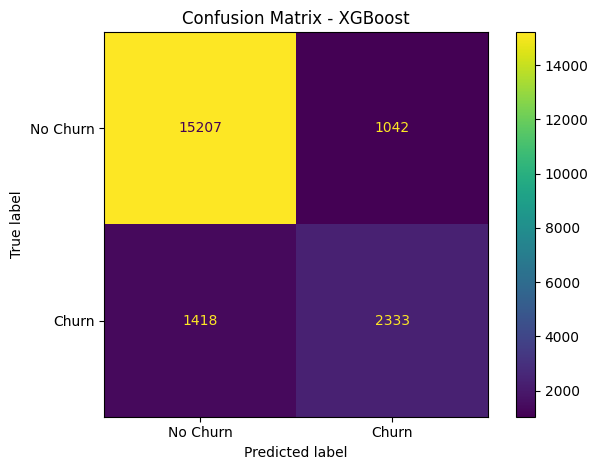

In [26]:
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Select XGBoost from the models already trained
best_model_name = "XGBoost"
best_model = trained_models[best_model_name]

# Predict customer churn on the held-out test set
y_pred = best_model.predict(X_test)

# Print detailed classification metrics
print(f"Classification Report: {best_model_name}")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=["No Churn", "Churn"],
        zero_division=0
    )
)

# Create and display the confusion matrix
cm = confusion_matrix(y_test, y_pred)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["No Churn", "Churn"]
)

display.plot()
plt.title(f"Confusion Matrix - {best_model_name}")
plt.tight_layout()
plt.show()

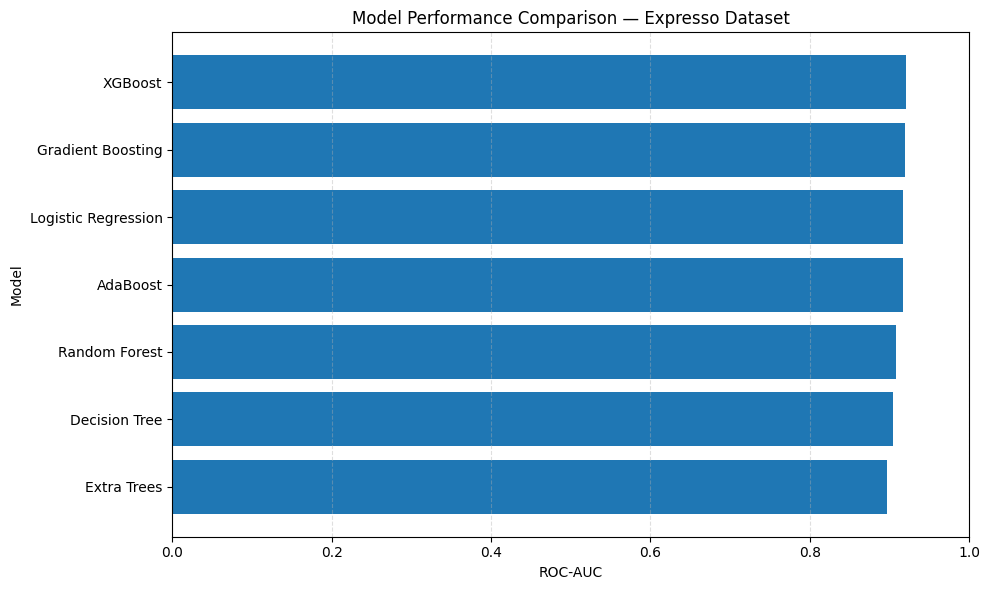

In [27]:
import matplotlib.pyplot as plt

# Plot ROC-AUC for every trained model
plot_df = results_df.sort_values("ROC_AUC", ascending=True)

plt.figure(figsize=(10, 6))
plt.barh(plot_df["Model"], plot_df["ROC_AUC"])

plt.xlabel("ROC-AUC")
plt.ylabel("Model")
plt.title("Model Performance Comparison — Expresso Dataset")
plt.xlim(0, 1)
plt.grid(axis="x", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

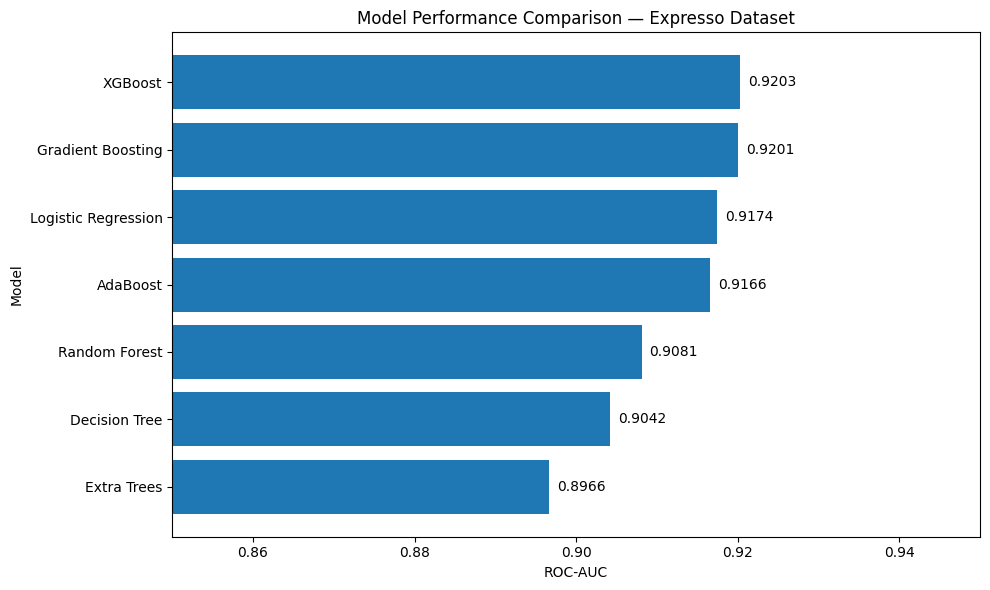

Chart saved to: C:\Users\Aman Sharma\Documents\Code\2026-10-02\official-dataset-information-the-project-must\ChurnSenseAI\reports\figures\expresso_model_comparison.png


In [28]:
from pathlib import Path
import matplotlib.pyplot as plt

output_dir = Path("../reports/figures")
output_dir.mkdir(parents=True, exist_ok=True)

plot_df = results_df.sort_values("ROC_AUC", ascending=True)

plt.figure(figsize=(10, 6))
plt.barh(plot_df["Model"], plot_df["ROC_AUC"])

plt.xlabel("ROC-AUC")
plt.ylabel("Model")
plt.title("Model Performance Comparison — Expresso Dataset")
plt.xlim(0.85, 0.95)

for i, score in enumerate(plot_df["ROC_AUC"]):
    plt.text(score + 0.001, i, f"{score:.4f}", va="center")

plt.tight_layout()

chart_path = output_dir / "expresso_model_comparison.png"
plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Chart saved to:", chart_path.resolve())

In [29]:
import pandas as pd
import matplotlib.pyplot as plt

# Get the fitted preprocessing and XGBoost model
preprocessor = trained_models["XGBoost"].named_steps["preprocessor"]
xgb_model = trained_models["XGBoost"].named_steps["model"]

# Get feature names after preprocessing
feature_names = preprocessor.get_feature_names_out()

# Extract XGBoost feature importance
importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": xgb_model.feature_importances_
})

# Display the 15 most important features
importance_df = importance_df.sort_values(
    "Importance", ascending=False
).reset_index(drop=True)

display(importance_df.head(15).round(4))

# Plot the top 15 features
top_features = importance_df.head(15).sort_values("Importance")

plt.figure(figsize=(10, 7))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Feature Importance")
plt.title("Top 15 Feature Importances — XGBoost")
plt.tight_layout()
plt.show()

TypeError: 'ConfusionMatrixDisplay' object is not callable

,Feature,Importance
0,numeric__missingindicator_REVENUE,0.2235
1,numeric__missingindicator_MONTANT,0.1736
2,numeric__REGULARITY,0.1637
3,categorical__REGION_DAKAR,0.1167
4,numeric__missingindicator_FREQUENCE_RECH,0.0432
5,numeric__missingindicator_FREQ_TOP_PACK,0.0260
6,numeric__missingindicator_ON_NET,0.0194
7,numeric__missingindicator_ORANGE,0.0180
8,numeric__missingindicator_FREQUENCE,0.0145
9,numeric__missingindicator_DATA_VOLUME,0.0094


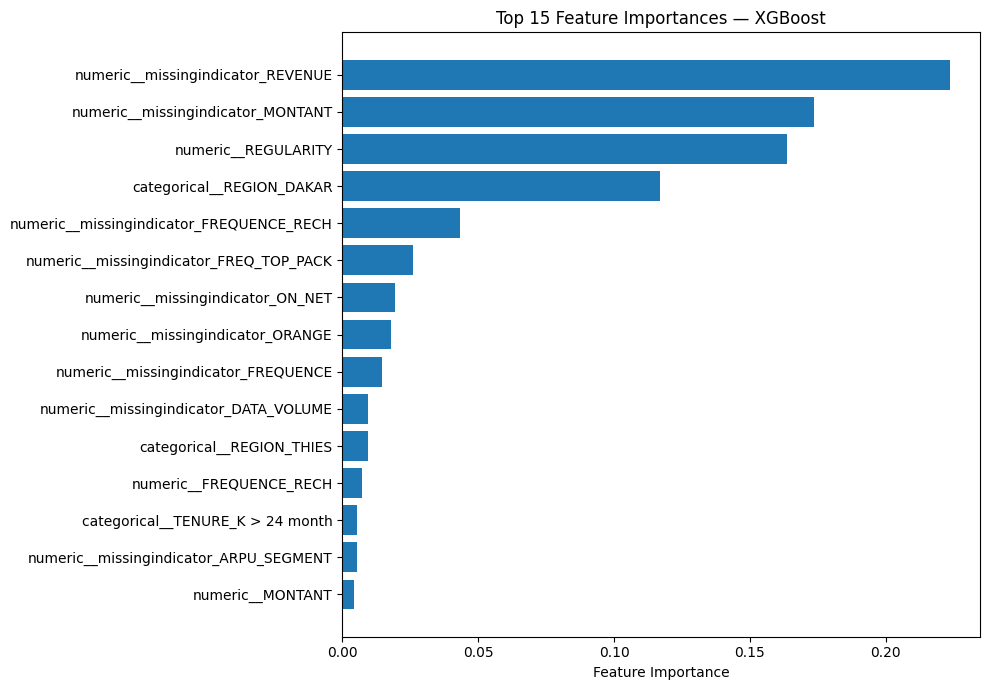

In [30]:
from IPython.display import display as show_table
import matplotlib.pyplot as plt
import pandas as pd

# Get the fitted XGBoost pipeline
xgb_pipeline = trained_models["XGBoost"]
preprocessor = xgb_pipeline.named_steps["preprocessor"]
xgb_model = xgb_pipeline.named_steps["model"]

# Get feature names and their importance scores
feature_names = preprocessor.get_feature_names_out()

importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": xgb_model.feature_importances_
})

# Display the 15 most important features
importance_df = importance_df.sort_values(
    "Importance", ascending=False
).reset_index(drop=True)

show_table(importance_df.head(15).round(4))

# Plot the top 15 features
top_features = importance_df.head(15).sort_values("Importance")

plt.figure(figsize=(10, 7))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Feature Importance")
plt.title("Top 15 Feature Importances — XGBoost")
plt.tight_layout()
plt.show()

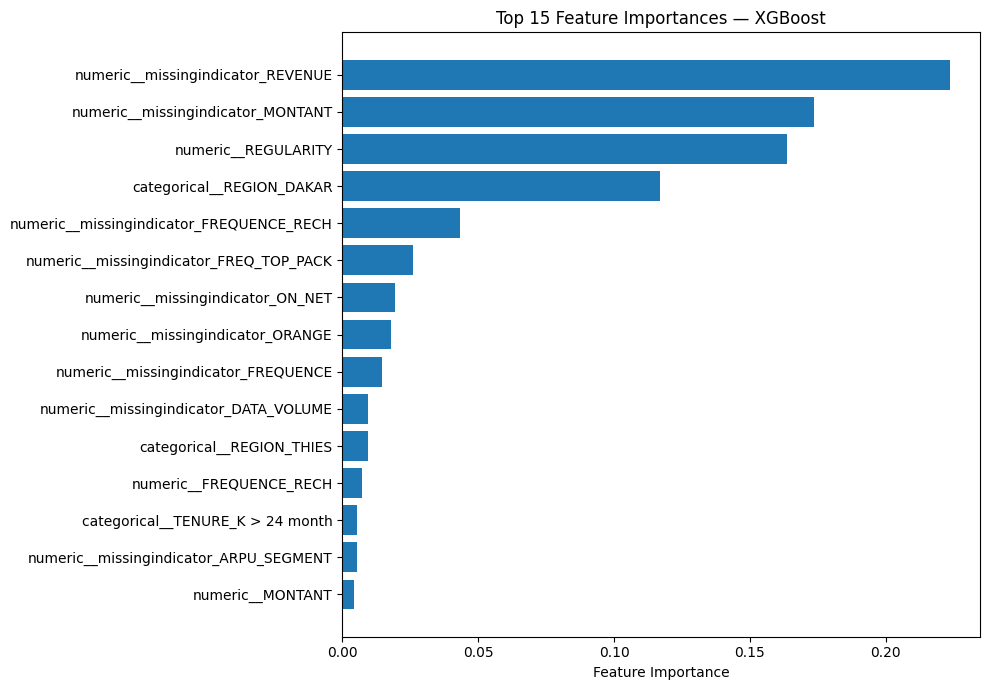

Feature table saved.
Chart saved: C:\Users\Aman Sharma\Documents\Code\2026-10-02\official-dataset-information-the-project-must\ChurnSenseAI\reports\figures\expresso_feature_importance.png


In [31]:
from pathlib import Path
import matplotlib.pyplot as plt

output_dir = Path("../reports/figures")
output_dir.mkdir(parents=True, exist_ok=True)

# Save the feature-importance table
importance_df.to_csv(
    output_dir.parent / "expresso_feature_importance.csv",
    index=False
)

# Save a high-resolution chart
top_features = importance_df.head(15).sort_values("Importance")

plt.figure(figsize=(10, 7))
plt.barh(top_features["Feature"], top_features["Importance"])
plt.xlabel("Feature Importance")
plt.title("Top 15 Feature Importances — XGBoost")
plt.tight_layout()

chart_path = output_dir / "expresso_feature_importance.png"
plt.savefig(chart_path, dpi=300, bbox_inches="tight")
plt.show()

print("Feature table saved.")
print("Chart saved:", chart_path.resolve())

In [32]:
# Check missing values in the original Expresso dataset

missing_summary = pd.DataFrame({
    "Missing_Count": df.isna().sum(),
    "Missing_Percentage": (df.isna().mean() * 100).round(2),
    "Data_Type": df.dtypes.astype(str)
})

missing_summary = missing_summary.sort_values(
    "Missing_Percentage",
    ascending=False
)

show_table(missing_summary)

print("Dataset shape:", df.shape)
print("Total missing cells:", int(df.isna().sum().sum()))
print("Duplicate rows:", int(df.duplicated().sum()))

,Missing_Count,Missing_Percentage,Data_Type
ZONE2,93586,93.59,float64
ZONE1,92071,92.07,float64
TIGO,59945,59.95,float64
DATA_VOLUME,49443,49.44,float64
TOP_PACK,41932,41.93,object
FREQ_TOP_PACK,41932,41.93,float64
ORANGE,41572,41.57,float64
REGION,39319,39.32,object
ON_NET,36635,36.64,float64
MONTANT,35244,35.24,float64


Dataset shape: (100000, 19)
Total missing cells: 668311
Duplicate rows: 0


In [33]:
# Compare missing-value rates for churn vs non-churn customers

missing_by_churn = df.groupby("CHURN").apply(
    lambda group: group.isna().mean() * 100,
    include_groups=False
)

# Keep only the feature columns, excluding the target
missing_by_churn = missing_by_churn.drop(
    columns=["CHURN"],
    errors="ignore"
).T

missing_by_churn.columns = [
    f"CHURN={column}" for column in missing_by_churn.columns
]

missing_by_churn["Difference_Percentage_Points"] = (
    missing_by_churn.iloc[:, 1] - missing_by_churn.iloc[:, 0]
)

missing_by_churn = missing_by_churn.sort_values(
    "Difference_Percentage_Points",
    key=abs,
    ascending=False
)

show_table(missing_by_churn.round(2))

,CHURN=0,CHURN=1,Difference_Percentage_Points
REGION,26.62,94.33,67.71
MONTANT,24.22,82.99,58.77
FREQUENCE_RECH,24.22,82.99,58.77
FREQUENCE,22.84,81.25,58.41
REVENUE,22.84,81.25,58.41
ARPU_SEGMENT,22.84,81.25,58.41
ORANGE,30.92,87.70,56.78
FREQ_TOP_PACK,31.31,87.94,56.63
TOP_PACK,31.31,87.94,56.63
ON_NET,26.06,82.46,56.40


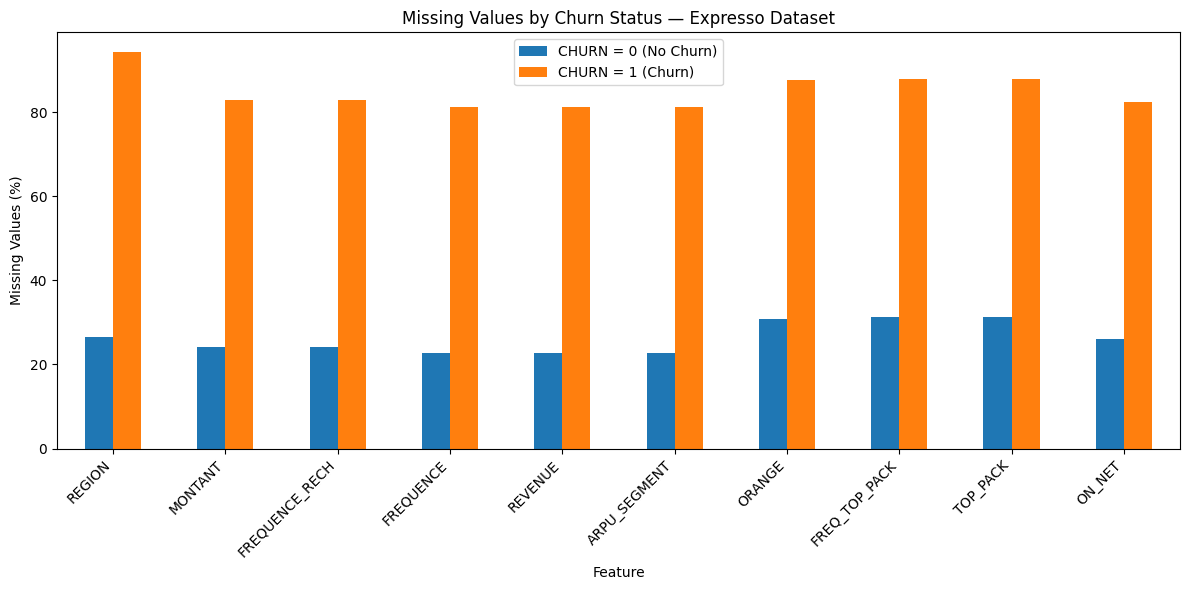

In [34]:
import matplotlib.pyplot as plt

# Calculate missing-value percentages for each churn group
missing_rates = df.groupby("CHURN").apply(
    lambda group: group.isna().mean() * 100,
    include_groups=False
).T

# Select the 10 features with the largest missingness differences
missing_rates["Difference"] = (
    missing_rates[1] - missing_rates[0]
)

top_features = (
    missing_rates["Difference"]
    .abs()
    .sort_values(ascending=False)
    .head(10)
    .index
)

plot_data = missing_rates.loc[top_features, [0, 1]]

# Plot a comparison
ax = plot_data.plot(
    kind="bar",
    figsize=(12, 6)
)

ax.set_title("Missing Values by Churn Status — Expresso Dataset")
ax.set_xlabel("Feature")
ax.set_ylabel("Missing Values (%)")
ax.set_xticklabels(ax.get_xticklabels(), rotation=45, ha="right")
ax.legend(["CHURN = 0 (No Churn)", "CHURN = 1 (Churn)"])
plt.tight_layout()
plt.show()

In [35]:
from sklearn.metrics import roc_auc_score
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
import pandas as pd

# Separate target and input features
X = df.drop(columns=["CHURN", "user_id"], errors="ignore")
y = df["CHURN"]

# Create train and test sets before fitting preprocessing
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Detect numeric and categorical columns
numeric_cols = X_train.select_dtypes(include="number").columns
categorical_cols = X_train.select_dtypes(
    exclude="number"
).columns

# Impute missing values using training data only
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="median", add_indicator=True
    ))
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(
        strategy="most_frequent"
    )),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_cols),
    ("categorical", categorical_pipeline, categorical_cols)
])

# Train a baseline model
baseline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=1000,
        class_weight="balanced"
    ))
])

baseline.fit(X_train, y_train)

probabilities = baseline.predict_proba(X_test)[:, 1]

print("Baseline ROC-AUC:", round(
    roc_auc_score(y_test, probabilities), 4
))
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))

Baseline ROC-AUC: 0.9039
Training rows: 80000
Testing rows: 20000


C:\Users\Aman Sharma\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 1000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=1000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


In [36]:
# Increase iterations and use a solver suitable for larger datasets
baseline.set_params(
    model__max_iter=3000,
    model__solver="saga",
    model__tol=0.001
)

# Retrain the same pipeline on the same training data
baseline.fit(X_train, y_train)

# Evaluate again on the same held-out test data
probabilities = baseline.predict_proba(X_test)[:, 1]

print(
    "Updated Baseline ROC-AUC:",
    round(roc_auc_score(y_test, probabilities), 4)
)

Updated Baseline ROC-AUC: 0.6597


In [37]:
import warnings
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline
from sklearn.metrics import roc_auc_score

for solver in ["lbfgs", "saga"]:
    print(f"\nTesting solver: {solver}")

    test_model = Pipeline([
        ("preprocessor", clone(preprocessor)),
        ("model", LogisticRegression(
            max_iter=3000,
            solver=solver,
            tol=0.001,
            class_weight="balanced",
            random_state=42
        ))
    ])

    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        test_model.fit(X_train, y_train)

    probs = test_model.predict_proba(X_test)[:, 1]

    print("ROC-AUC:", round(
        roc_auc_score(y_test, probs), 4
    ))
    print("Warnings:", [
        str(w.message)[:150] for w in caught
    ])
    


Testing solver: lbfgs
ROC-AUC: 0.9137
Warnings: ['lbfgs failed to converge after 3000 iteration(s) (status=1):\nSTOP: TOTAL NO. OF ITERATIONS REACHED LIMIT\n\nIncrease the number of iterations to improve']

Testing solver: saga
ROC-AUC: 0.6597
Warnings: []


In [38]:
from sklearn.base import clone
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
import warnings

scaled_numeric = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

scaled_preprocessor = ColumnTransformer([
    ("numeric", scaled_numeric, numeric_cols),
    ("categorical", categorical_pipeline, categorical_cols)
])

scaled_model = Pipeline([
    ("preprocessor", scaled_preprocessor),
    ("model", LogisticRegression(
        max_iter=3000,
        solver="lbfgs",
        class_weight="balanced",
        random_state=42
    ))
])

with warnings.catch_warnings(record=True) as caught:
    warnings.simplefilter("always")
    scaled_model.fit(X_train, y_train)

scaled_probs = scaled_model.predict_proba(X_test)[:, 1]

print("Scaled Logistic Regression ROC-AUC:",
      round(roc_auc_score(y_test, scaled_probs), 4))
print("Convergence warnings:",
      [str(w.message)[:180] for w in caught])

Scaled Logistic Regression ROC-AUC: 0.9174
Convergence warnings: []


In [39]:
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    GradientBoostingClassifier,
    AdaBoostClassifier,
    HistGradientBoostingClassifier
)
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)
import time
import pandas as pd

models_to_test = {
    "Logistic Regression": LogisticRegression(
        max_iter=3000,
        class_weight="balanced",
        random_state=42
    ),
    "Decision Tree": DecisionTreeClassifier(
        max_depth=10,
        class_weight="balanced",
        random_state=42
    ),
    "Random Forest": RandomForestClassifier(
        n_estimators=150,
        class_weight="balanced",
        n_jobs=-1,
        random_state=42
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=150,
        class_weight="balanced",
        n_jobs=-1,
        random_state=42
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    ),
    "AdaBoost": AdaBoostClassifier(
        random_state=42
    )
}

try:
    from xgboost import XGBClassifier

    models_to_test["XGBoost"] = XGBClassifier(
        n_estimators=250,
        max_depth=5,
        learning_rate=0.05,
        subsample=0.85,
        colsample_bytree=0.85,
        eval_metric="logloss",
        random_state=42,
        n_jobs=2
    )
except ImportError:
    print("XGBoost unavailable; skipping it.")

results = []
trained_models = {}

for name, estimator in models_to_test.items():
    print(f"Training {name}...")
    start = time.time()

    pipeline = Pipeline([
        ("preprocessor", clone(scaled_preprocessor)),
        ("model", estimator)
    ])

    pipeline.fit(X_train, y_train)

    probabilities = pipeline.predict_proba(X_test)[:, 1]
    predictions = (probabilities >= 0.5).astype(int)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1": f1_score(y_test, predictions, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, probabilities),
        "Training_Time_Seconds": round(time.time() - start, 2)
    })

    trained_models[name] = pipeline

results_df = pd.DataFrame(results).sort_values(
    "ROC_AUC", ascending=False
).reset_index(drop=True)

display(results_df.round(4))

Training Logistic Regression...
Training Decision Tree...
Training Random Forest...
Training Extra Trees...
Training Gradient Boosting...
Training AdaBoost...
Training XGBoost...


TypeError: 'ConfusionMatrixDisplay' object is not callable

In [40]:
from IPython.display import display as show_table

results_df = pd.DataFrame(results).sort_values(
    "ROC_AUC", ascending=False
).reset_index(drop=True)

show_table(results_df.round(4))

,Model,Accuracy,Precision,Recall,F1,ROC_AUC,Training_Time_Seconds
0,XGBoost,0.8770,0.6913,0.6220,0.6548,0.9203,2.08
1,Gradient Boosting,0.8770,0.6900,0.6244,0.6556,0.9201,18.14
2,Logistic Regression,0.8202,0.5120,0.8880,0.6495,0.9174,1.38
3,AdaBoost,0.8726,0.6587,0.6657,0.6622,0.9166,5.36
4,Random Forest,0.8526,0.5803,0.7723,0.6627,0.9079,21.48
5,Decision Tree,0.8202,0.5121,0.8747,0.6460,0.9043,1.97
6,Extra Trees,0.8473,0.5673,0.7827,0.6579,0.8968,31.17


In [41]:
from pathlib import Path

output_dir = Path("../reports")
output_dir.mkdir(parents=True, exist_ok=True)

output_file = output_dir / "expresso_model_comparison.csv"

results_df.to_csv(output_file, index=False)

print("Results saved successfully!")
print("Saved to:", output_file.resolve())

Results saved successfully!
Saved to: C:\Users\Aman Sharma\Documents\Code\2026-10-02\official-dataset-information-the-project-must\ChurnSenseAI\reports\expresso_model_comparison.csv


In [42]:
from sklearn.metrics import classification_report
from pathlib import Path

# Select the best model based on ROC-AUC
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

# Generate predictions on the existing test set
best_predictions = best_model.predict(X_test)

# Create a detailed classification report
report = classification_report(
    y_test,
    best_predictions,
    target_names=["No Churn", "Churn"],
    zero_division=0
)

print("Best model:", best_model_name)
print(report)

# Save the report
output_dir = Path("../reports")
output_dir.mkdir(parents=True, exist_ok=True)

report_file = output_dir / "expresso_classification_report.txt"
report_file.write_text(
    f"Best model: {best_model_name}\n\n{report}",
    encoding="utf-8"
)

print("Report saved to:", report_file.resolve())

Best model: XGBoost
              precision    recall  f1-score   support

    No Churn       0.91      0.94      0.93     16249
       Churn       0.69      0.62      0.65      3751

    accuracy                           0.88     20000
   macro avg       0.80      0.78      0.79     20000
weighted avg       0.87      0.88      0.87     20000

Report saved to: C:\Users\Aman Sharma\Documents\Code\2026-10-02\official-dataset-information-the-project-must\ChurnSenseAI\reports\expresso_classification_report.txt


In [43]:
import joblib
from pathlib import Path

# Create the models folder
models_dir = Path("../models")
models_dir.mkdir(parents=True, exist_ok=True)

# Save all trained models
joblib.dump(
    trained_models,
    models_dir / "expresso_all_models.joblib"
)

# Save the best model separately
best_model_name = results_df.iloc[0]["Model"]
best_model = trained_models[best_model_name]

joblib.dump(
    best_model,
    models_dir / "expresso_best_model.joblib"
)

print("All models saved successfully!")
print("Best model:", best_model_name)
print("Models folder:", models_dir.resolve())

All models saved successfully!
Best model: XGBoost
Models folder: C:\Users\Aman Sharma\Documents\Code\2026-10-02\official-dataset-information-the-project-must\ChurnSenseAI\models


In [44]:
import joblib
from pathlib import Path

models_dir = Path("../models")

# Load the saved best model
loaded_model = joblib.load(
    models_dir / "expresso_best_model.joblib"
)

# Test prediction on existing test data
sample_predictions = loaded_model.predict(X_test.iloc[:5])

print("Model loaded successfully!")
print("Sample predictions:", sample_predictions)
print("Expected output: 5 predictions")

Model loaded successfully!
Sample predictions: [1 0 0 0 0]
Expected output: 5 predictions


In [45]:
import pandas as pd

sample_data = X_test.iloc[:5]

probabilities = loaded_model.predict_proba(sample_data)[:, 1]
predictions = loaded_model.predict(sample_data)

prediction_results = pd.DataFrame({
    "Actual Churn": y_test.iloc[:5].values,
    "Predicted Churn": predictions,
    "Churn Probability (%)": (probabilities * 100).round(2)
})

display(prediction_results)

TypeError: 'ConfusionMatrixDisplay' object is not callable

In [46]:
from IPython.display import display as show_table

show_table(prediction_results)

,Actual Churn,Predicted Churn,Churn Probability (%)
0,0,1,75.910004
1,1,0,36.279999
2,0,0,0.250000
3,0,0,0.060000
4,0,0,5.200000


In [47]:
from pathlib import Path

output_dir = Path("../reports")
output_dir.mkdir(parents=True, exist_ok=True)

output_file = output_dir / "expresso_sample_predictions.csv"

prediction_results.to_csv(output_file, index=False)

print("Prediction results saved successfully!")
print("File:", output_file.resolve())

Prediction results saved successfully!
File: C:\Users\Aman Sharma\Documents\Code\2026-10-02\official-dataset-information-the-project-must\ChurnSenseAI\reports\expresso_sample_predictions.csv


In [48]:
from pathlib import Path

folders = {
    "Reports": Path("../reports"),
    "Models": Path("../models"),
}

for folder_name, folder_path in folders.items():
    print(f"\n{folder_name} folder:")

    if folder_path.exists():
        files = sorted(
            p for p in folder_path.iterdir() if p.is_file()
        )

        for file in files:
            print(f"  {file.name} ({file.stat().st_size:,} bytes)")
    else:
        print("  Folder not found")


Reports folder:
  customer_risk_segments.csv (1,727,119 bytes)
  data_summary.csv (74 bytes)
  expresso_classification_report.txt (357 bytes)
  expresso_feature_importance.csv (7,076 bytes)
  expresso_model_comparison.csv (787 bytes)
  expresso_sample_predictions.csv (103 bytes)
  model_comparison.csv (241 bytes)
  shap_importance.csv (1,082 bytes)

Models folder:
  all_models.joblib (17,519,379 bytes)
  best_model.joblib (486,048 bytes)
  expresso_all_models.joblib (462,670,838 bytes)
  expresso_best_model.joblib (591,329 bytes)
  model_metadata.json (578 bytes)


In [49]:
import pandas as pd
import joblib
from pathlib import Path

model_path = Path("../models/expresso_best_model.joblib")
data_path = Path("../data/expresso.csv")

print("Model exists:", model_path.exists())
print("Dataset exists:", data_path.exists())


Model exists: True
Dataset exists: False


In [50]:
from pathlib import Path

data_dir = Path("../data")

print("CSV files in data folder:")
for file in data_dir.glob("*.csv"):
    print(file.name)

CSV files in data folder:
WA_Fn-UseC_-Telco-Customer-Churn.csv


In [51]:
from pathlib import Path

project_dir = Path("..")

for file in project_dir.rglob("*.csv"):
    if "expresso" in file.name.lower():
        print(file)

..\reports\expresso_feature_importance.csv
..\reports\expresso_model_comparison.csv
..\reports\expresso_sample_predictions.csv
..\data\raw\Expresso_churn_100k.csv
..\data\raw\Expresso_churn_dataset.csv


In [52]:
import pandas as pd
from pathlib import Path

data_dir = Path("../data/raw")

for file in data_dir.glob("*Expresso*.csv"):
    df = pd.read_csv(file, nrows=5)

    print(f"\nFile: {file.name}")
    print("Shape (first 5 rows):", df.shape)
    print("Columns:", df.columns.tolist())
    print(df.head(2))


File: Expresso_churn_100k.csv
Shape (first 5 rows): (5, 19)
Columns: ['user_id', 'REGION', 'TENURE', 'MONTANT', 'FREQUENCE_RECH', 'REVENUE', 'ARPU_SEGMENT', 'FREQUENCE', 'DATA_VOLUME', 'ON_NET', 'ORANGE', 'TIGO', 'ZONE1', 'ZONE2', 'MRG', 'REGULARITY', 'TOP_PACK', 'FREQ_TOP_PACK', 'CHURN']
                                    user_id REGION        TENURE  MONTANT  \
0  1e3e1c8230db145ea073760453df1aed2e4d883b  DAKAR  K > 24 month  12600.0   
1  9e38efcd2d0d87e1c500c6917bfc037d1bca3e3c    NaN  K > 24 month   4550.0   

   FREQUENCE_RECH  REVENUE  ARPU_SEGMENT  FREQUENCE  DATA_VOLUME  ON_NET  \
0            27.0  13101.0        4367.0       27.0          0.0   507.0   
1            15.0   5347.0        1782.0       20.0        261.0   633.0   

   ORANGE   TIGO  ZONE1  ZONE2 MRG  REGULARITY  \
0   107.0  165.0    NaN    NaN  NO          58   
1    48.0    1.0    NaN    NaN  NO          45   

                         TOP_PACK  FREQ_TOP_PACK  CHURN  
0           All-net 500F=2000F;5d      

In [53]:
import pandas as pd
from pathlib import Path

data_dir = Path("../data/raw")

files = [
    data_dir / "Expresso_churn_100k.csv",
    data_dir / "Expresso_churn_dataset.csv"
]

for file in files:
    df = pd.read_csv(file)

    print(f"\n{'=' * 50}")
    print("File:", file.name)
    print("Rows and columns:", df.shape)
    print("Duplicate rows:", df.duplicated().sum())
    print("Duplicate user IDs:", df["user_id"].duplicated().sum())
    print("Churn distribution:")
    print(df["CHURN"].value_counts(dropna=False))
    print("Missing target values:", df["CHURN"].isna().sum())


File: Expresso_churn_100k.csv
Rows and columns: (100000, 19)
Duplicate rows: 0
Duplicate user IDs: 0
Churn distribution:
CHURN
0    81245
1    18755
Name: count, dtype: int64
Missing target values: 0

File: Expresso_churn_dataset.csv
Rows and columns: (2154048, 19)
Duplicate rows: 0
Duplicate user IDs: 0
Churn distribution:
CHURN
0    1750062
1     403986
Name: count, dtype: int64
Missing target values: 0


In [54]:
import pandas as pd
from pathlib import Path

file = Path("../data/raw/Expresso_churn_100k.csv")
df = pd.read_csv(file)

quality = pd.DataFrame({
    "Data Type": df.dtypes.astype(str),
    "Missing Count": df.isna().sum(),
    "Missing %": (df.isna().mean() * 100).round(2),
    "Unique Values": df.nunique()
})

display(quality.sort_values("Missing %", ascending=False))

print("\nTarget distribution (%):")
print((df["CHURN"].value_counts(normalize=True) * 100).round(2))

print("\nTarget values:", sorted(df["CHURN"].unique()))

TypeError: 'ConfusionMatrixDisplay' object is not callable

In [55]:
from IPython.display import display as show_table

show_table(quality.sort_values("Missing %", ascending=False))

print("\nTarget distribution (%):")
print((df["CHURN"].value_counts(normalize=True) * 100).round(2))

print("\nTarget values:", sorted(df["CHURN"].unique()))

,Data Type,Missing Count,Missing %,Unique Values
ZONE2,float64,93586,93.59,155
ZONE1,float64,92071,92.07,186
TIGO,float64,59945,59.95,520
DATA_VOLUME,float64,49443,49.44,11443
TOP_PACK,object,41932,41.93,98
FREQ_TOP_PACK,float64,41932,41.93,127
ORANGE,float64,41572,41.57,1354
REGION,object,39319,39.32,14
ON_NET,float64,36635,36.64,3456
MONTANT,float64,35244,35.24,1252



Target distribution (%):
CHURN
0    81.24
1    18.76
Name: proportion, dtype: float64

Target values: [np.int64(0), np.int64(1)]


In [56]:
# Compare missing-value percentages for each churn class

missing_by_churn = (
    df.groupby("CHURN")
      .apply(lambda group: group.isna().mean() * 100)
      .T
)

missing_by_churn.columns = ["CHURN=0", "CHURN=1"]

missing_by_churn["Difference"] = (
    missing_by_churn["CHURN=1"] - missing_by_churn["CHURN=0"]
).abs()

missing_by_churn = missing_by_churn.sort_values(
    "Difference", ascending=False
)

show_table(missing_by_churn.round(2))

C:\Users\Aman Sharma\AppData\Local\Temp\ipykernel_14088\2885648691.py:5: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  .apply(lambda group: group.isna().mean() * 100)


,CHURN=0,CHURN=1,Difference
REGION,26.62,94.33,67.71
FREQUENCE_RECH,24.22,82.99,58.77
MONTANT,24.22,82.99,58.77
FREQUENCE,22.84,81.25,58.41
ARPU_SEGMENT,22.84,81.25,58.41
REVENUE,22.84,81.25,58.41
ORANGE,30.92,87.70,56.78
TOP_PACK,31.31,87.94,56.63
FREQ_TOP_PACK,31.31,87.94,56.63
ON_NET,26.06,82.46,56.40


In [57]:
# Inspect each column's data type and missing-value percentage

column_profile = pd.DataFrame({
    "Data_Type": df.dtypes.astype(str),
    "Missing_Count": df.isna().sum(),
    "Missing_Percentage": (df.isna().mean() * 100).round(2),
    "Unique_Values": df.nunique()
})

show_table(
    column_profile.sort_values(
        "Missing_Percentage", ascending=False
    )
)

,Data_Type,Missing_Count,Missing_Percentage,Unique_Values
ZONE2,float64,93586,93.59,155
ZONE1,float64,92071,92.07,186
TIGO,float64,59945,59.95,520
DATA_VOLUME,float64,49443,49.44,11443
TOP_PACK,object,41932,41.93,98
FREQ_TOP_PACK,float64,41932,41.93,127
ORANGE,float64,41572,41.57,1354
REGION,object,39319,39.32,14
ON_NET,float64,36635,36.64,3456
MONTANT,float64,35244,35.24,1252


In [58]:
from pathlib import Path

data_dir = Path("../data/raw")

for file in data_dir.glob("*.csv"):
    print(file.name, file.stat().st_size, "bytes")

Expresso_churn_100k.csv 12122414 bytes
Expresso_churn_dataset.csv 259026777 bytes


In [59]:
import pandas as pd
from pathlib import Path

data_path = Path("../data/raw/Expresso_churn_100k.csv")
expresso_df = pd.read_csv(data_path)

print("Dataset shape:", expresso_df.shape)
print("Target distribution:")
print(expresso_df["CHURN"].value_counts(normalize=True).mul(100).round(2))

Dataset shape: (100000, 19)
Target distribution:
CHURN
0    81.24
1    18.76
Name: proportion, dtype: float64


In [60]:
from sklearn.model_selection import train_test_split

# Separate target from input features
X = expresso_df.drop(columns=["CHURN", "user_id"])
y = expresso_df["CHURN"]

# Split before fitting any preprocessing
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    stratify=y,
    random_state=42
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])
print("Training churn rate:", round(y_train.mean() * 100, 2), "%")
print("Testing churn rate:", round(y_test.mean() * 100, 2), "%")

Training rows: 80000
Testing rows: 20000
Training churn rate: 18.76 %
Testing churn rate: 18.76 %


In [61]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.base import clone

# Identify column types from the training data
numeric_cols = X_train.select_dtypes(include="number").columns.tolist()
categorical_cols = X_train.select_dtypes(exclude="number").columns.tolist()

print("Numeric columns:", numeric_cols)
print("Categorical columns:", categorical_cols)

# Preprocessing for numeric columns
numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median", add_indicator=True))
])

# Preprocessing for categorical columns
categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine both preprocessing pipelines
preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_cols),
    ("categorical", categorical_pipeline, categorical_cols)
])

# Keep preprocessing and model together
model_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

print("Pipeline created successfully.")

Numeric columns: ['MONTANT', 'FREQUENCE_RECH', 'REVENUE', 'ARPU_SEGMENT', 'FREQUENCE', 'DATA_VOLUME', 'ON_NET', 'ORANGE', 'TIGO', 'ZONE1', 'ZONE2', 'REGULARITY', 'FREQ_TOP_PACK']
Categorical columns: ['REGION', 'TENURE', 'MRG', 'TOP_PACK']
Pipeline created successfully.


In [62]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    classification_report
)
import pandas as pd

# Train the complete pipeline
model_pipeline.fit(X_train, y_train)

# Predict labels and churn probabilities
y_pred = model_pipeline.predict(X_test)
y_prob = model_pipeline.predict_proba(X_test)[:, 1]

# Calculate evaluation metrics
metrics = {
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, zero_division=0),
    "Recall": recall_score(y_test, y_pred, zero_division=0),
    "F1 Score": f1_score(y_test, y_pred, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, y_prob)
}

display(pd.DataFrame([metrics]).round(4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Churn", "Churn"],
    zero_division=0
))

C:\Users\Aman Sharma\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=2000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


TypeError: 'ConfusionMatrixDisplay' object is not callable

In [ ]:
from IPython.display import display as show_table

show_table(pd.DataFrame([metrics]).round(4))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    target_names=["No Churn", "Churn"],
    zero_division=0
))

In [63]:

# Inspect the most incomplete columns
missing_summary = (
    expresso_df.isna()
    .mean()
    .mul(100)
    .sort_values(ascending=False)
    .rename("Missing_Percentage")
    .to_frame()
)

show_table(missing_summary.round(2))

,Missing_Percentage
ZONE2,93.59
ZONE1,92.07
TIGO,59.95
DATA_VOLUME,49.44
TOP_PACK,41.93
FREQ_TOP_PACK,41.93
ORANGE,41.57
REGION,39.32
ON_NET,36.64
MONTANT,35.24


In [64]:
# Inspect the data type and number of unique values
column_summary = pd.DataFrame({
    "Data_Type": expresso_df.dtypes.astype(str),
    "Unique_Values": expresso_df.nunique(),
    "Missing_Percentage": (
        expresso_df.isna().mean() * 100
    ).round(2)
})

show_table(column_summary)

,Data_Type,Unique_Values,Missing_Percentage
user_id,object,100000,0.00
REGION,object,14,39.32
TENURE,object,8,0.00
MONTANT,float64,1252,35.24
FREQUENCE_RECH,float64,101,35.24
REVENUE,float64,13557,33.80
ARPU_SEGMENT,float64,7254,33.80
FREQUENCE,float64,91,33.80
DATA_VOLUME,float64,11443,49.44
ON_NET,float64,3456,36.64


In [65]:
# Inspect the values in categorical and high-missingness columns
columns_to_inspect = [
    "TENURE",
    "MRG",
    "REGION",
    "TOP_PACK",
    "ZONE1",
    "ZONE2",
    "CHURN"
]

for col in columns_to_inspect:
    print(f"\n{'=' * 50}")
    print(f"Column: {col}")
    print(f"Unique values: {expresso_df[col].nunique()}")
    print(expresso_df[col].value_counts(dropna=False).head(15))


Column: TENURE
Unique values: 8
TENURE
K > 24 month     94766
I 18-21 month     2105
H 15-18 month     1240
G 12-15 month      729
J 21-24 month      579
F 9-12 month       450
E 6-9 month         91
D 3-6 month         40
Name: count, dtype: int64

Column: MRG
Unique values: 1
MRG
NO    100000
Name: count, dtype: int64

Column: REGION
Unique values: 14
REGION
NaN            39319
DAKAR          23846
THIES           8552
SAINT-LOUIS     5670
KAOLACK         4553
LOUGA           4541
DIOURBEL        3086
TAMBACOUNDA     2454
KAFFRINE        2142
KOLDA           1745
FATICK          1613
MATAM           1358
ZIGUINCHOR       951
SEDHIOU          128
KEDOUGOU          42
Name: count, dtype: int64

Column: TOP_PACK
Unique values: 98
TOP_PACK
NaN                                          41932
All-net 500F=2000F;5d                        14752
On net 200F=Unlimited _call24H                6953
Data:490F=1GB,7d                              5201
Data: 100 F=40MB,24H                          

In [66]:

# Compare churn rates for missing vs. available values

columns_to_check = [
    "REGION",
    "TOP_PACK",
    "ZONE1",
    "ZONE2",
    "DATA_VOLUME",
    "TIGO"
]

missingness_results = []

for col in columns_to_check:
    missing = expresso_df[col].isna()

    missingness_results.append({
        "Column": col,
        "Missing_Rows": int(missing.sum()),
        "Missing_Churn_Rate_%": round(
            expresso_df.loc[missing, "CHURN"].mean() * 100, 2
        ) if missing.any() else None,
        "Available_Churn_Rate_%": round(
            expresso_df.loc[~missing, "CHURN"].mean() * 100, 2
        ) if (~missing).any() else None
    })

missingness_df = pd.DataFrame(missingness_results)
show_table(missingness_df)



,Column,Missing_Rows,Missing_Churn_Rate_%,Available_Churn_Rate_%
0,REGION,39319,44.99,1.75
1,TOP_PACK,41932,39.33,3.90
2,ZONE1,92071,19.98,4.50
3,ZONE2,93586,19.68,5.24
4,DATA_VOLUME,49443,30.45,7.32
5,TIGO,59945,29.25,3.05


In [67]:

# Check whether missing values occur together

columns_to_check = [
    "REGION",
    "TOP_PACK",
    "ZONE1",
    "ZONE2",
    "DATA_VOLUME",
    "TIGO"
]

missing_flags = expresso_df[columns_to_check].isna()

print("Missing-value correlation:")
show_table(missing_flags.corr().round(2))

print("\nNumber of missing fields per customer:")
show_table(
    missing_flags.sum(axis=1)
    .value_counts()
    .sort_index()
    .rename_axis("Missing_Field_Count")
    .reset_index(name="Customer_Count")
)


Missing-value correlation:


,REGION,TOP_PACK,ZONE1,ZONE2,DATA_VOLUME,TIGO
REGION,1.00,0.47,0.11,0.08,0.28,0.37
TOP_PACK,0.47,1.00,0.19,0.16,0.46,0.58
ZONE1,0.11,0.19,1.00,0.11,0.11,0.17
ZONE2,0.08,0.16,0.11,1.00,0.12,0.14
DATA_VOLUME,0.28,0.46,0.11,0.12,1.00,0.29
TIGO,0.37,0.58,0.17,0.14,0.29,1.00



Number of missing fields per customer:


,Missing_Field_Count,Customer_Count
0,0,518
1,1,4936
2,2,21242
3,3,22645
4,4,15019
5,5,12975
6,6,22665


In [68]:

# Experiment: test whether missingness indicators help predict churn

from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)
import pandas as pd

# Use the train/test split already created earlier.
# Add missingness indicators to the input features.
X_train_missing = X_train.copy()
X_test_missing = X_test.copy()

X_train_missing = X_train_missing.assign(
    **X_train_missing.isna().add_prefix("missing_").astype(int)
)
X_test_missing = X_test_missing.assign(
    **X_test_missing.isna().add_prefix("missing_").astype(int)
)

# Identify numeric and categorical columns from the training data.
numeric_cols = X_train_missing.select_dtypes(
    include="number"
).columns.tolist()

categorical_cols = X_train_missing.select_dtypes(
    exclude="number"
).columns.tolist()

numeric_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("numeric", numeric_pipeline, numeric_cols),
    ("categorical", categorical_pipeline, categorical_cols)
])

model = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42
    ))
])

model.fit(X_train_missing, y_train)
predictions = model.predict(X_test_missing)
probabilities = model.predict_proba(X_test_missing)[:, 1]

results = pd.DataFrame([{
    "Precision": precision_score(y_test, predictions, zero_division=0),
    "Recall": recall_score(y_test, predictions, zero_division=0),
    "F1": f1_score(y_test, predictions, zero_division=0),
    "ROC_AUC": roc_auc_score(y_test, probabilities)
}])

display(results.round(4))


TypeError: 'ConfusionMatrixDisplay' object is not callable

In [ ]:
from IPython.display import display as show_table

show_table(results.round(4))

In [69]:

import pandas as pd
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score
)
from IPython.display import display as show_table

# Both experiments use the same existing train/test split.

def build_preprocessor(features, add_all_missing_flags=False):
    numeric_cols = features.select_dtypes(include="number").columns.tolist()
    categorical_cols = features.select_dtypes(exclude="number").columns.tolist()

    numeric_steps = [
        ("imputer", SimpleImputer(
            strategy="median",
            add_indicator=not add_all_missing_flags
        )),
        ("scaler", StandardScaler())
    ]

    numeric_pipeline = Pipeline(numeric_steps)

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    transformers = [
        ("numeric", numeric_pipeline, numeric_cols),
        ("categorical", categorical_pipeline, categorical_cols)
    ]

    return ColumnTransformer(transformers)


def run_experiment(name, Xtr, Xte, explicit_flags=False):
    preprocessor = build_preprocessor(
        Xtr,
        add_all_missing_flags=explicit_flags
    )

    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        ))
    ])

    pipeline.fit(Xtr, y_train)

    predictions = pipeline.predict(Xte)
    probabilities = pipeline.predict_proba(Xte)[:, 1]

    return {
        "Experiment": name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(
            y_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_test, predictions, zero_division=0
        ),
        "F1": f1_score(y_test, predictions, zero_division=0),
        "ROC_AUC": roc_auc_score(y_test, probabilities)
    }


# A: Standard preprocessing, with numeric missingness indicators.
result_a = run_experiment(
    "A - Standard preprocessing",
    X_train,
    X_test
)

# B: Explicit missingness indicators for all original features.
X_train_flags = pd.concat(
    [
        X_train,
        X_train.isna().astype(int).add_prefix("missing_")
    ],
    axis=1
)

X_test_flags = pd.concat(
    [
        X_test,
        X_test.isna().astype(int).add_prefix("missing_")
    ],
    axis=1
)

result_b = run_experiment(
    "B - Explicit missingness flags",
    X_train_flags,
    X_test_flags,
    explicit_flags=True
)

comparison = pd.DataFrame([result_a, result_b]).set_index("Experiment")
show_table(comparison.round(4))


,Accuracy,Precision,Recall,F1,ROC_AUC
Experiment,,,,,
A - Standard preprocessing,0.8202,0.5120,0.8880,0.6495,0.9174
B - Explicit missingness flags,0.8420,0.5481,0.8984,0.6808,0.9302


### Experiment: Impact of Explicit Missingness Indicators

**Objective:** Evaluate whether adding explicit missingness indicators improves customer churn prediction on the 100,000-row Expresso sample.

**Method:** Two Logistic Regression pipelines were evaluated using the same existing stratified train/test split, `random_state=42`, and `class_weight="balanced"`. Experiment A used standard preprocessing with numeric missingness indicators. Experiment B added explicit missingness flags for all original features.

**Results:** Experiment B achieved an accuracy of 84.20%, precision of 54.81%, recall of 89.84%, F1-score of 68.08%, and ROC-AUC of 0.9302. All five metrics were higher than those of Experiment A.

**Conclusion:** Explicit missingness indicators are promising for the Expresso dataset. The improvement should be validated with repeated or cross-validated experiments and tested on another dataset before adopting this as a universal preprocessing strategy.

**Limitation:** Predictive associations between missingness and churn do not establish causation. Missingness may reflect the dataset's collection process or customer activity patterns.

In [70]:

import numpy as np
import pandas as pd

from sklearn.base import clone
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression

# Use only the training data for cross-validation.
# The held-out test set remains untouched.

def make_cv_pipeline(X, explicit_flags=False):
    numeric_cols = X.select_dtypes(include="number").columns.tolist()
    categorical_cols = X.select_dtypes(exclude="number").columns.tolist()

    numeric_pipeline = Pipeline([
        ("imputer", SimpleImputer(
            strategy="median",
            add_indicator=not explicit_flags
        )),
        ("scaler", StandardScaler())
    ])

    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("encoder", OneHotEncoder(handle_unknown="ignore"))
    ])

    preprocessor = ColumnTransformer([
        ("numeric", numeric_pipeline, numeric_cols),
        ("categorical", categorical_pipeline, categorical_cols)
    ])

    return Pipeline([
        ("preprocessor", preprocessor),
        ("model", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=42
        ))
    ])

# Add explicit missingness flags for Experiment B.
X_cv_flags = pd.concat([
    X_train,
    X_train.isna().astype(int).add_prefix("missing_")
], axis=1)

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

scores_a = cross_val_score(
    make_cv_pipeline(X_train),
    X_train,
    y_train,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)

scores_b = cross_val_score(
    make_cv_pipeline(X_cv_flags, explicit_flags=True),
    X_cv_flags,
    y_train,
    cv=cv,
    scoring="roc_auc",
    n_jobs=-1
)

cv_results = pd.DataFrame({
    "Fold": [1, 2, 3],
    "A - Standard": scores_a,
    "B - Explicit missingness flags": scores_b
})

from IPython.display import display as show_table
show_table(cv_results.round(4))

print("Mean ROC-AUC — A:", round(scores_a.mean(), 4))
print("Mean ROC-AUC — B:", round(scores_b.mean(), 4))


,Fold,A - Standard,B - Explicit missingness flags
0,1,0.9111,0.9261
1,2,0.9142,0.9290
2,3,0.9131,0.9269


Mean ROC-AUC — A: 0.9128
Mean ROC-AUC — B: 0.9273


### Experiment: Three-Fold Cross-Validation of Missingness Indicators

**Objective:** Assess whether explicit missingness indicators improve the ROC-AUC of the Expresso churn model across multiple training/validation folds.

**Method:** Standard preprocessing (Experiment A) was compared with explicit missingness indicators for all original features (Experiment B). Both used Logistic Regression, class-weighted training, and three-fold stratified cross-validation on the training partition.

**Results:**
- Experiment A mean ROC-AUC: 0.9128
- Experiment B mean ROC-AUC: 0.9273
- Mean improvement: 0.0145
- Experiment B achieved higher ROC-AUC in all three folds.

**Conclusion:** Explicit missingness indicators are a promising preprocessing option for the Expresso dataset. They will be evaluated on a second dataset before being considered for the general-purpose ChurnSense AI pipeline.

**Limitations:** Cross-validation was performed on one dataset. The improvement does not establish causation or guarantee generalization to other datasets.

In [73]:

from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

from src.pipeline import prepare_training_data, make_model_pipeline

# Load the 100k Expresso sample
expresso_df = pd.read_csv("../data/raw/Expresso_churn_100k.csv")

# Prepare features and target using the updated project module
X, y = prepare_training_data(
    expresso_df,
    target="CHURN",
    id_column="user_id",
)

# Create a fresh, reproducible train/test split
X_train_test, X_test_test, y_train_test, y_test_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y,
)

# Enable explicit missingness indicators
pipeline = make_model_pipeline(
    X_train_test,
    LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42,
    ),
    add_missing_flags=True,
)

pipeline.fit(X_train_test, y_train_test)

probabilities = pipeline.predict_proba(X_test_test)[:, 1]

print("Test ROC-AUC:", round(
    roc_auc_score(y_test_test, probabilities), 4
))
print("Pipeline test completed successfully.")


Test ROC-AUC: 0.9302
Pipeline test completed successfully.


In [72]:

import importlib
import src.pipeline as pipeline_module

importlib.reload(pipeline_module)

prepare_training_data = pipeline_module.prepare_training_data
make_model_pipeline = pipeline_module.make_model_pipeline

print("Updated pipeline module loaded successfully.")


Updated pipeline module loaded successfully.


In [74]:

# Test the default configuration (missingness flags disabled)
pipeline_standard = make_model_pipeline(
    X_train_test,
    LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42,
    ),
)

pipeline_standard.fit(X_train_test, y_train_test)

standard_probabilities = pipeline_standard.predict_proba(X_test_test)[:, 1]

print(
    "Standard pipeline ROC-AUC:",
    round(roc_auc_score(y_test_test, standard_probabilities), 4)
)
print("Standard pipeline test completed successfully.")


Standard pipeline ROC-AUC: 0.9174
Standard pipeline test completed successfully.


In [76]:

from pathlib import Path

# Search for the Telco CSV starting from the current notebook directory
search_roots = [
    Path.cwd(),
    Path.cwd().parent,
    Path.home() / "Documents",
]

matches = []

for root in search_roots:
    if root.exists():
        matches.extend(
            p for p in root.rglob("WA_Fn-Use-C_-Telco-Customer-Churn.csv")
            if p.is_file()
        )

matches = list(dict.fromkeys(matches))

if matches:
    for i, path in enumerate(matches, start=1):
        print(f"{i}. {path.resolve()}")
else:
    print("CSV not found in the searched folders.")
    print("Current notebook directory:", Path.cwd())


CSV not found in the searched folders.
Current notebook directory: C:\Users\Aman Sharma\Documents\Code\2026-10-02\official-dataset-information-the-project-must\ChurnSenseAI\notebooks


In [77]:

from pathlib import Path
import pandas as pd

project_root = Path.cwd().parent

telco_path = project_root / "data" / "WA_Fn-UseC_-Telco-Customer-Churn.csv"

telco_df = pd.read_csv(telco_path)

print("Dataset shape:", telco_df.shape)
print("\nTarget distribution:")
print(telco_df["Churn"].value_counts(dropna=False))
print("\nMissing target values:", telco_df["Churn"].isna().sum())


Dataset shape: (7043, 21)

Target distribution:
Churn
No     5174
Yes    1869
Name: count, dtype: int64

Missing target values: 0


In [78]:

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from src.pipeline import prepare_training_data, make_model_pipeline
from IPython.display import display as show_table

# 1. Prepare the IBM Telco dataset
X_telco, y_telco = prepare_training_data(
    telco_df,
    target="Churn",
    id_column="customerID",
)

# 2. Create one shared, stratified 80/20 split
X_train_telco, X_test_telco, y_train_telco, y_test_telco = (
    train_test_split(
        X_telco,
        y_telco,
        test_size=0.20,
        random_state=42,
        stratify=y_telco,
    )
)

# 3. Experiment A: Standard preprocessing
model_a = make_model_pipeline(
    X_train_telco,
    LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42,
    ),
)

model_a.fit(X_train_telco, y_train_telco)
proba_a = model_a.predict_proba(X_test_telco)[:, 1]

# 4. Experiment B: Explicit missingness indicators
model_b = make_model_pipeline(
    X_train_telco,
    LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42,
    ),
    add_missing_flags=True,
)

model_b.fit(X_train_telco, y_train_telco)
proba_b = model_b.predict_proba(X_test_telco)[:, 1]

# 5. Compare held-out ROC-AUC scores
telco_comparison = pd.DataFrame({
    "Experiment": [
        "A - Standard preprocessing",
        "B - Explicit missingness flags",
    ],
    "ROC_AUC": [
        roc_auc_score(y_test_telco, proba_a),
        roc_auc_score(y_test_telco, proba_b),
    ],
})

show_table(telco_comparison.round(4))


,Experiment,ROC_AUC
0,A - Standard preprocessing,0.8401
1,B - Explicit missingness flags,0.8401


In [79]:

print("Feature data types:")
print(X_telco.dtypes)

print("\nMissing values in the original Telco features:")
missing_counts = X_telco.isna().sum()
print(missing_counts[missing_counts > 0].sort_values(ascending=False))

print("\nTotalCharges column type:")
print(telco_df["TotalCharges"].dtype)



Feature data types:
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
dtype: object

Missing values in the original Telco features:
Series([], dtype: int64)

TotalCharges column type:
object


In [80]:

# Inspect TotalCharges before changing anything
print("Original data type:", telco_df["TotalCharges"].dtype)

print("\nValues that are blank or whitespace:")
blank_mask = telco_df["TotalCharges"].astype(str).str.strip().eq("")
print("Blank entries:", int(blank_mask.sum()))

# Test numeric conversion on a separate Series
total_charges_test = pd.to_numeric(
    telco_df["TotalCharges"].astype(str).str.strip(),
    errors="coerce",
)

print("\nMissing values after test conversion:", int(total_charges_test.isna().sum()))
print("Converted data type:", total_charges_test.dtype)
print("\nSample converted values:")
print(total_charges_test.head(10))


Original data type: object

Values that are blank or whitespace:
Blank entries: 11

Missing values after test conversion: 11
Converted data type: float64

Sample converted values:
0      29.85
1    1889.50
2     108.15
3    1840.75
4     151.65
5     820.50
6    1949.40
7     301.90
8    3046.05
9    3487.95
Name: TotalCharges, dtype: float64


In [81]:

import importlib
import src.pipeline as pipeline_module

# Load the updated source code
importlib.reload(pipeline_module)

prepare_training_data = pipeline_module.prepare_training_data
make_model_pipeline = pipeline_module.make_model_pipeline

# Prepare the Telco dataset again
X_telco, y_telco = prepare_training_data(
    telco_df,
    target="Churn",
    id_column="customerID",
)

print("Telco feature shape:", X_telco.shape)
print("\nTotalCharges data type:", X_telco["TotalCharges"].dtype)
print("TotalCharges missing values:", X_telco["TotalCharges"].isna().sum())

print("\nNumeric features:")
print(X_telco.select_dtypes(include="number").columns.tolist())

print("\nCategorical features:")
print(X_telco.select_dtypes(exclude="number").columns.tolist())


Telco feature shape: (7043, 19)

TotalCharges data type: object
TotalCharges missing values: 0

Numeric features:
['SeniorCitizen', 'tenure', 'MonthlyCharges']

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'TotalCharges']


In [82]:

# Inspect the original values and test conversion directly
raw = telco_df["TotalCharges"].astype("string").str.strip()

print("Original column type:", telco_df["TotalCharges"].dtype)
print("Blank strings after stripping:", int(raw.eq("").sum()))

converted = pd.to_numeric(raw.replace("", pd.NA), errors="coerce")

print("\nConverted column type:", converted.dtype)
print("Missing values after conversion:", int(converted.isna().sum()))
print("\nValues that failed numeric conversion:")
print(telco_df.loc[converted.isna(), "TotalCharges"].head(20).tolist())


Original column type: object
Blank strings after stripping: 11

Converted column type: Float64
Missing values after conversion: 11

Values that failed numeric conversion:
[' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ', ' ']


In [83]:

import importlib
import src.pipeline as pipeline_module

# Reload the updated pipeline code
importlib.reload(pipeline_module)

prepare_training_data = pipeline_module.prepare_training_data
make_model_pipeline = pipeline_module.make_model_pipeline

# Prepare the Telco dataset
X_telco, y_telco = prepare_training_data(
    telco_df,
    target="Churn",
    id_column="customerID",
)

# Verify the fix
print("Feature shape:", X_telco.shape)
print("\nTotalCharges data type:", X_telco["TotalCharges"].dtype)
print("TotalCharges missing values:", X_telco["TotalCharges"].isna().sum())

print("\nNumeric features:")
print(X_telco.select_dtypes(include="number").columns.tolist())

print("\nCategorical features:")
print(X_telco.select_dtypes(exclude="number").columns.tolist())


Feature shape: (7043, 19)

TotalCharges data type: Float64
TotalCharges missing values: 11

Numeric features:
['SeniorCitizen', 'tenure', 'MonthlyCharges', 'TotalCharges']

Categorical features:
['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


In [84]:

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, roc_auc_score, classification_report

# Split the dataset before fitting preprocessing
X_train, X_test, y_train, y_test = train_test_split(
    X_telco,
    y_telco,
    test_size=0.20,
    random_state=42,
    stratify=y_telco,
)

# Build and train the reusable pipeline
model = make_model_pipeline(
    X_train,
    LogisticRegression(max_iter=2000, class_weight="balanced", random_state=42),
)

model.fit(X_train, y_train)

# Evaluate on unseen test data
predictions = model.predict(X_test)
probabilities = model.predict_proba(X_test)[:, 1]

print("Model training: SUCCESS")
print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Accuracy:", round(accuracy_score(y_test, predictions), 4))
print("ROC-AUC:", round(roc_auc_score(y_test, probabilities), 4))

print("\nClassification Report:")
print(classification_report(y_test, predictions))


Model training: SUCCESS
Training rows: 5634
Testing rows: 1409
Accuracy: 0.7388
ROC-AUC: 0.8418

Classification Report:
              precision    recall  f1-score   support

          No       0.90      0.72      0.80      1035
         Yes       0.51      0.78      0.61       374

    accuracy                           0.74      1409
   macro avg       0.70      0.75      0.71      1409
weighted avg       0.80      0.74      0.75      1409



In [85]:

# Prepare the Expresso dataset using the same pipeline
X_expresso, y_expresso = prepare_training_data(
    expresso_df,
    target="CHURN",
    id_column="user_id",
)

print("Expresso feature shape:", X_expresso.shape)
print("Target distribution:")
print(y_expresso.value_counts())

print("\nNumeric features:")
print(X_expresso.select_dtypes(include="number").columns.tolist())

print("\nCategorical features:")
print(X_expresso.select_dtypes(exclude="number").columns.tolist())

# Create a separate train/test split
X_exp_train, X_exp_test, y_exp_train, y_exp_test = train_test_split(
    X_expresso,
    y_expresso,
    test_size=0.20,
    random_state=42,
    stratify=y_expresso,
)

# Train the same kind of model through the reusable pipeline
expresso_model = make_model_pipeline(
    X_exp_train,
    LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        random_state=42,
    ),
)

expresso_model.fit(X_exp_train, y_exp_train)

expresso_predictions = expresso_model.predict(X_exp_test)
expresso_probabilities = expresso_model.predict_proba(X_exp_test)[:, 1]

print("\nExpresso model training: SUCCESS")
print("Training rows:", len(X_exp_train))
print("Testing rows:", len(X_exp_test))
print("Accuracy:", round(accuracy_score(y_exp_test, expresso_predictions), 4))
print("ROC-AUC:", round(roc_auc_score(y_exp_test, expresso_probabilities), 4))
print("\nClassification Report:")
print(classification_report(y_exp_test, expresso_predictions))



Expresso feature shape: (100000, 16)
Target distribution:
CHURN
0    81245
1    18755
Name: count, dtype: int64

Numeric features:
['MONTANT', 'FREQUENCE_RECH', 'REVENUE', 'ARPU_SEGMENT', 'FREQUENCE', 'DATA_VOLUME', 'ON_NET', 'ORANGE', 'TIGO', 'ZONE1', 'ZONE2', 'REGULARITY', 'FREQ_TOP_PACK']

Categorical features:
['REGION', 'TENURE', 'TOP_PACK']

Expresso model training: SUCCESS
Training rows: 80000
Testing rows: 20000
Accuracy: 0.8204
ROC-AUC: 0.9174

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.80      0.88     16249
           1       0.51      0.89      0.65      3751

    accuracy                           0.82     20000
   macro avg       0.74      0.85      0.76     20000
weighted avg       0.88      0.82      0.84     20000

